In [ ]:
%pip install stargazer

In [ ]:
import pandas as pd
import statsmodels.api as sm
from stargazer.stargazer import Stargazer

#**Weekly Survey Data**

In [ ]:
# Load the data
from google.colab import drive
drive.mount('/content/drive')
file_path = '/content/4_weekly_survey_with_personality.csv'


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
weekly_data = pd.read_csv(file_path)
weekly_data.head()

,id_participant,timestamp,This app is easy to use.,How often do you wear your watch in a week?,The notifications on the watch were annoying.,The notifications on the phone were annoying.,I answered the the question on the watch honestly.,The Cozie app feels fast and responsive.,The notifications helped to change my mind.,I changed my location after seeing the notifications.,...,"Over the past week, I put on my earphones to mitigate noise distractions after receiving the noise intervention messages.","Over the past week, I changed my location, adjusted the thermostat, fan etc. to feel thermally comfortable after receiving the temperature intervention messages.",The intervention messages were annoying.,Extraversion,Agreeableness,Conscientiousness,Emotional Stability,Openness to Experience,swls,sensitivity
0,orenth01,2022-10-10 14:22:56.671000+00:00,Strongly disagree,40-50 hours,Neutral,Neutral,Strongly disagree,Strongly disagree,Somewhat agree,Very rarely,...,NaN,NaN,NaN,3.5,6.0,3.0,5.5,3.0,22,4.250000
1,orenth01,2022-10-20 01:44:32.965000+00:00,Strongly disagree,>50 hours,Strongly disagree,Strongly disagree,Strongly disagree,Agree,Agree,Rarely,...,NaN,NaN,NaN,3.5,6.0,3.0,5.5,3.0,22,4.250000
2,orenth01,2022-10-26 07:31:27.555000+00:00,Neutral,>50 hours,Agree,Agree,Strong Agree,Agree,Agree,Occasionally,...,NaN,NaN,NaN,3.5,6.0,3.0,5.5,3.0,22,4.250000
3,orenth02,2022-10-12 01:13:47.044000+00:00,Agree,10-20 hours,Disagree,Neutral,Strong Agree,Agree,Agree,Rarely,...,NaN,NaN,NaN,4.5,3.5,5.0,5.5,4.0,26,4.666667
4,orenth02,2022-10-17 01:01:01.540000+00:00,Strong Agree,<10 hours,Disagree,Neutral,Agree,Agree,Agree,Occasionally,...,NaN,NaN,NaN,4.5,3.5,5.0,5.5,4.0,26,4.666667


In [ ]:
weekly_data.shape

(430, 25)

In [ ]:
weekly_data.id_participant.nunique()

103

In [ ]:
weekly_data.columns

Index(['id_participant', 'timestamp', 'This app is easy to use.',
       'How often do you wear your watch in a week?',
       'The notifications on the watch were annoying.',
       'The notifications on the phone were annoying.',
       'I answered the the question on the watch honestly.',
       'The Cozie app feels fast and responsive.',
       'The notifications helped to change my mind.',
       'I changed my location after seeing the notifications.',
       'Overall, how satisfied are you with the Cozie app?',
       'How would you rate the overall quality of the app?',
       'How likely are you to recommend this app to a friend or colleague?',
       'The noise and/or temperature intervention messages were helpful to me in understanding how to improve my indoor environmental satisfaction.',
       'Over the past week, I changed my location after receiving the noise intervention messages. ',
       'Over the past week, I put on my earphones to mitigate noise distractions after 

#**Missing Values Treatment**

In [ ]:
def handle_missing_values(df, columns, strategy='drop', fill_value=None):

    # Create a copy of the DataFrame to avoid modifying the original
    result_df = df.copy()

    if strategy == 'drop':
        # Drop rows where any of the specified columns have missing values
        result_df = result_df.dropna(subset=columns)
    elif strategy == 'fill':
        # Check if fill_value is provided
        if fill_value is None:
            raise ValueError("fill_value must be provided when strategy is 'fill'.")

        # Fill missing values in the specified columns with fill_value
        for column in columns:
            result_df[column] = result_df[column].fillna(fill_value)
    else:
        raise ValueError("strategy must be either 'drop' or 'fill'.")

    return result_df

In [ ]:
chosen_columns = [
    'The noise and/or temperature intervention messages were helpful to me in understanding how to improve my indoor environmental satisfaction.',
    'Over the past week, I changed my location after receiving the noise intervention messages. ',
    'Over the past week, I put on my earphones to mitigate noise distractions after receiving the noise intervention messages.',
    'Over the past week, I changed my location, adjusted the thermostat, fan etc. to feel thermally comfortable after receiving the temperature intervention messages.',
    'The intervention messages were annoying.'
]

predicted_columns = chosen_columns

In [ ]:
# choose the drop option
df_drop = handle_missing_values(weekly_data, columns=predicted_columns, strategy='drop')
# df_drop = handle_missing_values(weekly_data, columns=predicted_columns, strategy='fill', fill_value=0)
df_drop.shape

(360, 25)

In [ ]:
df_drop

,id_participant,timestamp,This app is easy to use.,How often do you wear your watch in a week?,The notifications on the watch were annoying.,The notifications on the phone were annoying.,I answered the the question on the watch honestly.,The Cozie app feels fast and responsive.,The notifications helped to change my mind.,I changed my location after seeing the notifications.,...,"Over the past week, I put on my earphones to mitigate noise distractions after receiving the noise intervention messages.","Over the past week, I changed my location, adjusted the thermostat, fan etc. to feel thermally comfortable after receiving the temperature intervention messages.",The intervention messages were annoying.,Extraversion,Agreeableness,Conscientiousness,Emotional Stability,Openness to Experience,swls,sensitivity
37,orenth12,2022-11-23 01:14:35.141000+00:00,Neutral,30-40 hours,NaN,NaN,NaN,Agree,NaN,NaN,...,Often,Often,Agree,3.5,6.0,5.0,6.0,4.0,24,4.500000
38,orenth12,2022-11-25 05:09:51.624000+00:00,Agree,30-40 hours,NaN,NaN,NaN,Agree,NaN,NaN,...,Often,Always,Disgree,3.5,6.0,5.0,6.0,4.0,24,4.500000
39,orenth12,2022-11-29 14:05:23.043000+00:00,Agree,30-40 hours,NaN,NaN,NaN,Agree,NaN,NaN,...,Often,Often,Disgree,3.5,6.0,5.0,6.0,4.0,24,4.500000
47,orenth14,2022-11-26 10:14:10.774000+00:00,Strongly agree,40-50 hours,NaN,NaN,NaN,Agree,NaN,NaN,...,Often,Often,Disgree,4.5,5.0,6.0,4.0,5.5,24,4.916667
51,orenth15,2022-11-25 16:47:46.748000+00:00,Agree,20-30 hours,NaN,NaN,NaN,Neutral,NaN,NaN,...,Never,Never,Neutral,3.5,5.0,3.5,4.0,4.0,23,4.583333
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
425,usk55,2023-06-09 16:18:34.998000+00:00,Agree,30-40 hours,NaN,NaN,NaN,Neutral,NaN,NaN,...,Seldom,Never,Neutral,3.0,5.5,6.5,3.0,6.5,13,4.750000
426,usk56,2023-05-21 04:53:13.177000+00:00,Strongly agree,10-20 hours,NaN,NaN,NaN,Agree,NaN,NaN,...,No intervention messages received,Seldom,Neutral,5.0,4.5,4.5,5.5,5.0,23,4.416667
427,usk56,2023-05-24 01:04:41.697000+00:00,Strongly agree,10-20 hours,NaN,NaN,NaN,Strongly agree,NaN,NaN,...,Seldom,Seldom,Neutral,5.0,4.5,4.5,5.5,5.0,23,4.416667
428,usk56,2023-05-31 01:04:39.258000+00:00,Strongly agree,<10 hours,NaN,NaN,NaN,Strongly agree,NaN,NaN,...,Seldom,Sometimes,Agree,5.0,4.5,4.5,5.5,5.0,23,4.416667


In [ ]:
df_drop = df_drop[['id_participant', 'timestamp'] + predicted_columns]
df_drop
df_drop=df_drop[df_drop.apply(lambda row:all (row!='No intervention messages received'),axis=1)]

In [ ]:
df_drop.head(10)

,id_participant,timestamp,The noise and/or temperature intervention messages were helpful to me in understanding how to improve my indoor environmental satisfaction.,"Over the past week, I changed my location after receiving the noise intervention messages.","Over the past week, I put on my earphones to mitigate noise distractions after receiving the noise intervention messages.","Over the past week, I changed my location, adjusted the thermostat, fan etc. to feel thermally comfortable after receiving the temperature intervention messages.",The intervention messages were annoying.
37,orenth12,2022-11-23 01:14:35.141000+00:00,Agree,Often,Often,Often,Agree
38,orenth12,2022-11-25 05:09:51.624000+00:00,Agree,Often,Often,Always,Disgree
39,orenth12,2022-11-29 14:05:23.043000+00:00,Agree,Often,Often,Often,Disgree
47,orenth14,2022-11-26 10:14:10.774000+00:00,Agree,Seldom,Often,Often,Disgree
51,orenth15,2022-11-25 16:47:46.748000+00:00,Disagree,Never,Never,Never,Neutral
52,orenth15,2022-11-30 07:01:14.398000+00:00,Disagree,Never,Never,Never,Neutral
57,orenth16,2022-11-30 07:04:47.484000+00:00,Strongly agree,Seldom,Never,Sometimes,Strongly disagree
60,orenth17,2022-11-25 07:32:18.897000+00:00,Agree,Never,Never,Never,Disgree
63,orenth18,2022-11-25 01:15:27.548000+00:00,Neutral,Never,Never,Seldom,Neutral
64,orenth18,2022-11-29 13:23:14.762000+00:00,Agree,Never,Never,Never,Neutral


In [ ]:
from tabulate import tabulate
 #assuming df_drop is your dataframe and predicted_columns is your list of columns

for col in predicted_columns:
    print(f"**{col} ({df_drop[col].dtype}) Value Counts**\n")
    print(tabulate(pd.DataFrame(df_drop[col].value_counts()), headers=['Value', 'Count'], tablefmt='fancy_grid'))
    print()  # empty line for better readability

**The noise and/or temperature intervention messages were helpful to me in understanding how to improve my indoor environmental satisfaction. (object) Value Counts**

╒═══════════════════╤═════════╕
│ Value             │   Count │
╞═══════════════════╪═════════╡
│ Agree             │     136 │
├───────────────────┼─────────┤
│ Neutral           │      68 │
├───────────────────┼─────────┤
│ Disagree          │      46 │
├───────────────────┼─────────┤
│ Strongly agree    │      21 │
├───────────────────┼─────────┤
│ Strongly disagree │      10 │
╘═══════════════════╧═════════╛

**Over the past week, I changed my location after receiving the noise intervention messages.  (object) Value Counts**

╒═══════════╤═════════╕
│ Value     │   Count │
╞═══════════╪═════════╡
│ Never     │     117 │
├───────────┼─────────┤
│ Sometimes │      83 │
├───────────┼─────────┤
│ Seldom    │      52 │
├───────────┼─────────┤
│ Often     │      26 │
├───────────┼─────────┤
│ Always    │       3 │
╘════════

In [ ]:
agree_mapping = {
    'Strongly agree': 5,
    'Agree': 4,
    'Neutral': 3,
    'Disagree': 2,
    'Disgree': 2, # typo in the data
    'Strongly disagree': 1,
}
frequency_mapping = {
    'Always': 5,
    'Often': 4,
    'Sometimes': 3,
    'Seldom': 2,
    'Never': 1,
}

In [ ]:
agree_columns = [predicted_columns[0], predicted_columns[4]]
frequency_columns = predicted_columns[1:4]
print(frequency_columns)

['Over the past week, I changed my location after receiving the noise intervention messages. ', 'Over the past week, I put on my earphones to mitigate noise distractions after receiving the noise intervention messages.', 'Over the past week, I changed my location, adjusted the thermostat, fan etc. to feel thermally comfortable after receiving the temperature intervention messages.']


In [ ]:
overall_strategy_mapping = {
    'agree_columns': [agree_columns, agree_mapping],
    'frequency_columns': [frequency_columns, frequency_mapping]
}

def strategy_mapping_to_numeric(df: pd.DataFrame, strategy_mapping: dict):
    for _, [columns,mapping] in strategy_mapping.items():
            for column in columns:
                df[column] = df[column].replace(mapping)
# do the mapping
strategy_mapping_to_numeric(df_drop, overall_strategy_mapping)

<ipython-input-493-279f6301b045>:9: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df[column] = df[column].replace(mapping)
<ipython-input-493-279f6301b045>:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[column] = df[column].replace(mapping)


In [ ]:
df_drop

,id_participant,timestamp,The noise and/or temperature intervention messages were helpful to me in understanding how to improve my indoor environmental satisfaction.,"Over the past week, I changed my location after receiving the noise intervention messages.","Over the past week, I put on my earphones to mitigate noise distractions after receiving the noise intervention messages.","Over the past week, I changed my location, adjusted the thermostat, fan etc. to feel thermally comfortable after receiving the temperature intervention messages.",The intervention messages were annoying.
37,orenth12,2022-11-23 01:14:35.141000+00:00,4,4,4,4,4
38,orenth12,2022-11-25 05:09:51.624000+00:00,4,4,4,5,2
39,orenth12,2022-11-29 14:05:23.043000+00:00,4,4,4,4,2
47,orenth14,2022-11-26 10:14:10.774000+00:00,4,2,4,4,2
51,orenth15,2022-11-25 16:47:46.748000+00:00,2,1,1,1,3
...,...,...,...,...,...,...,...
423,usk55,2023-05-21 08:17:53.989000+00:00,3,1,2,2,3
424,usk55,2023-05-26 11:09:39.204000+00:00,2,2,1,1,3
425,usk55,2023-06-09 16:18:34.998000+00:00,2,1,2,1,3
427,usk56,2023-05-24 01:04:41.697000+00:00,4,2,2,2,3


In [ ]:
df_drop.id_participant.nunique()

80

In [ ]:
# check if any values in the data is not integer
df_drop.dtypes

,0
id_participant,object
timestamp,object
The noise and/or temperature intervention messages were helpful to me in understanding how to improve my indoor environmental satisfaction.,int64
"Over the past week, I changed my location after receiving the noise intervention messages.",int64
"Over the past week, I put on my earphones to mitigate noise distractions after receiving the noise intervention messages.",int64
"Over the past week, I changed my location, adjusted the thermostat, fan etc. to feel thermally comfortable after receiving the temperature intervention messages.",int64
The intervention messages were annoying.,int64


#**Personality Data**

In [ ]:
file_path1 = '/content/3_all_personality_scores.csv'
data_personality = pd.read_csv(file_path1)


In [ ]:
data_personality['sensitivity'] = data_personality['sensitivity'].round(2)
data_personality.head()

,id_participant,Extraversion,Agreeableness,Conscientiousness,Emotional Stability,Openness to Experience,swls,sensitivity
0,orenth01,3.5,6.0,3.0,5.5,3.0,22,4.25
1,orenth02,4.5,3.5,5.0,5.5,4.0,26,4.67
2,orenth03,2.0,5.5,3.0,2.5,4.5,20,4.50
3,orenth04,3.0,5.5,4.0,3.0,4.5,18,5.25
4,orenth05,4.0,4.5,4.0,4.0,4.5,24,4.33


In [ ]:
data_personality = data_personality.rename(columns={
    'swls': 'SWLS_score',
    'sensitivity': 'HSP_score'
})


In [ ]:
# remove the column with suffix _text or _level
data_personality = data_personality[data_personality.columns.drop(list(data_personality.filter(regex='_text')))]
data_personality = data_personality[data_personality.columns.drop(list(data_personality.filter(regex='_level')))]
# rename Experiment tag (for example orenth04, provided by the researcher) to id_participant
data_personality = data_personality.rename(columns={'Experiment tag (for example orenth04, provided by the researcher)': 'id_participant'})
data_personality

,id_participant,Extraversion,Agreeableness,Conscientiousness,Emotional Stability,Openness to Experience,SWLS_score,HSP_score
0,orenth01,3.5,6.0,3.0,5.5,3.0,22,4.25
1,orenth02,4.5,3.5,5.0,5.5,4.0,26,4.67
2,orenth03,2.0,5.5,3.0,2.5,4.5,20,4.50
3,orenth04,3.0,5.5,4.0,3.0,4.5,18,5.25
4,orenth05,4.0,4.5,4.0,4.0,4.5,24,4.33
...,...,...,...,...,...,...,...,...
98,usk52,6.5,7.0,7.0,6.0,6.5,35,4.67
99,usk53,3.0,2.5,6.5,2.0,4.0,20,4.08
100,usk54,6.0,4.0,6.0,5.5,5.5,16,3.67
101,usk55,3.0,5.5,6.5,3.0,6.5,13,4.75


#**Merge Weekly & Personality Data**

In [ ]:
# merge the two dataframes, using id_participant as the key
# keep all the rows in the left dataframe (df_drop) - fill those rows with value as long as the id_participant is in the right dataframe (data_personality)
df_merged_temp = pd.merge(df_drop, data_personality, on='id_participant', how='left')

df_merged_temp

,id_participant,timestamp,The noise and/or temperature intervention messages were helpful to me in understanding how to improve my indoor environmental satisfaction.,"Over the past week, I changed my location after receiving the noise intervention messages.","Over the past week, I put on my earphones to mitigate noise distractions after receiving the noise intervention messages.","Over the past week, I changed my location, adjusted the thermostat, fan etc. to feel thermally comfortable after receiving the temperature intervention messages.",The intervention messages were annoying.,Extraversion,Agreeableness,Conscientiousness,Emotional Stability,Openness to Experience,SWLS_score,HSP_score
0,orenth12,2022-11-23 01:14:35.141000+00:00,4,4,4,4,4,3.5,6.0,5.0,6.0,4.0,24,4.50
1,orenth12,2022-11-25 05:09:51.624000+00:00,4,4,4,5,2,3.5,6.0,5.0,6.0,4.0,24,4.50
2,orenth12,2022-11-29 14:05:23.043000+00:00,4,4,4,4,2,3.5,6.0,5.0,6.0,4.0,24,4.50
3,orenth14,2022-11-26 10:14:10.774000+00:00,4,2,4,4,2,4.5,5.0,6.0,4.0,5.5,24,4.92
4,orenth15,2022-11-25 16:47:46.748000+00:00,2,1,1,1,3,3.5,5.0,3.5,4.0,4.0,23,4.58
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
276,usk55,2023-05-21 08:17:53.989000+00:00,3,1,2,2,3,3.0,5.5,6.5,3.0,6.5,13,4.75
277,usk55,2023-05-26 11:09:39.204000+00:00,2,2,1,1,3,3.0,5.5,6.5,3.0,6.5,13,4.75
278,usk55,2023-06-09 16:18:34.998000+00:00,2,1,2,1,3,3.0,5.5,6.5,3.0,6.5,13,4.75
279,usk56,2023-05-24 01:04:41.697000+00:00,4,2,2,2,3,5.0,4.5,4.5,5.5,5.0,23,4.42


#**Merging All Onboarding Variables**


In [ ]:
# read the data
file_path3 = '/content/1_onboarding_survey_all_participants.csv'
all_onboarding_data = pd.read_csv(file_path3)


In [ ]:
from datetime import datetime

# Columns you want to drop
columns_to_drop = [
    'index',  # newly added
    'Start Date',
    'End Date',
    'Progress',
    'Duration (in seconds)',
    'Finished',
    'Recorded Date'
]

# Drop only the columns that are actually present
existing_cols = [col for col in columns_to_drop if col in all_onboarding_data.columns]
all_onboarding_data.drop(columns=existing_cols, inplace=True)

# Clean and rename participant ID column
all_onboarding_data.rename(
    columns={'Experiment tag (for example orenth04, provided by the researcher)': 'id_participant'},
    inplace=True
)
all_onboarding_data['id_participant'] = all_onboarding_data['id_participant'].str.lower().str.strip()

# Remove specific participants
all_onboarding_data = all_onboarding_data[
    ~all_onboarding_data['id_participant'].isin(['usk12', 'orenth30', 'orenth47'])
]

# Convert Year of birth to Age
if 'Year of birth (for example 1995)' in all_onboarding_data.columns:
    current_year = datetime.now().year
    all_onboarding_data['Age'] = current_year - pd.to_numeric(
        all_onboarding_data['Year of birth (for example 1995)'], errors='coerce'
    )
    all_onboarding_data.drop(columns=['Year of birth (for example 1995)'], inplace=True)

# Final shape check
print(all_onboarding_data.shape)


(103, 76)


In [ ]:
df = all_onboarding_data.copy()


In [ ]:
# all the mapping dict here
satisfaction_mapping = {
    'Not applicable': 0,
    'Neither satisfied nor dissatisfied': 4,
    'Slightly satisfied': 5,
    'Slightly dissatisfied': 3,
    'Moderately satisfied': 6,
    'Moderately dissatisfied': 2,
    'Extremely satisfied': 7,
    'Extremely dissatisfied': 1
}
yes_no_mapping = {'Yes': 1, 'No': 0}
gender_mapping = {'Female': 0, 'Male': 1}
agree_mapping = {
    'Strongly disagree': 1,
    'Disagree': 2,
    'Somewhat disagree': 3,
    'Neither agree nor disagree': 4,
    'Somewhat agree': 5,
    'Agree': 6,
    'Strongly agree': 7
}
importance_mapping = {
    'Not at all important': 0,
    'Slightly important': 1,
    'Moderately important': 2,
    'Very important': 3,
    'Extremely important': 4
}

sensitive_noise_mapping = {
    'Not at all': 0,
    'Slightly': 1,
    'Moderately': 2,
    'Very': 3,
    'Extremely': 4
}



In [ ]:
satisfaction_columns = [
       'Can you say that you are satisfied with the weather in Singapore (outdoor weather conditions)?',
       "In the space type(s) you mentioned above, generally how satisfied are you with the noise level? (If you did not use a certain space type, indicate 'Not applicable') - Private office",
       "In the space type(s) you mentioned above, generally how satisfied are you with the noise level? (If you did not use a certain space type, indicate 'Not applicable') - Open-plan office",
       "In the space type(s) you mentioned above, generally how satisfied are you with the noise level? (If you did not use a certain space type, indicate 'Not applicable') - Cubicle office",
       "In the space type(s) you mentioned above, generally how satisfied are you with the noise level? (If you did not use a certain space type, indicate 'Not applicable') - Home desk",
       "In the space type(s) you mentioned above, generally how satisfied are you with the noise level? (If you did not use a certain space type, indicate 'Not applicable') - Classroom",
       "In the space type(s) you mentioned above, generally how satisfied are you with the noise level? (If you did not use a certain space type, indicate 'Not applicable') - Hot-desking office",
       "In the space type(s) you mentioned above, generally how satisfied are you with the noise level? (If you did not use a certain space type, indicate 'Not applicable') - Others (please indicate the type of space in the text box below)",
       "In the space type(s) you mentioned above, generally  how satisfied are you with the sound privacy (ability to have conversations without your neighbours overhearing and vice versa)? (If you did not use a certain space type, indicate 'Not applicable') - Private office",
       "In the space type(s) you mentioned above, generally  how satisfied are you with the sound privacy (ability to have conversations without your neighbours overhearing and vice versa)? (If you did not use a certain space type, indicate 'Not applicable') - Open-plan office",
       "In the space type(s) you mentioned above, generally  how satisfied are you with the sound privacy (ability to have conversations without your neighbours overhearing and vice versa)? (If you did not use a certain space type, indicate 'Not applicable') - Cubicle office",
       "In the space type(s) you mentioned above, generally  how satisfied are you with the sound privacy (ability to have conversations without your neighbours overhearing and vice versa)? (If you did not use a certain space type, indicate 'Not applicable') - Home desk",
       "In the space type(s) you mentioned above, generally  how satisfied are you with the sound privacy (ability to have conversations without your neighbours overhearing and vice versa)? (If you did not use a certain space type, indicate 'Not applicable') - Classroom",
       "In the space type(s) you mentioned above, generally  how satisfied are you with the sound privacy (ability to have conversations without your neighbours overhearing and vice versa)? (If you did not use a certain space type, indicate 'Not applicable') - Hot-desking office",
       "In the space type(s) you mentioned above, generally  how satisfied are you with the sound privacy (ability to have conversations without your neighbours overhearing and vice versa)? (If you did not use a certain space type, indicate 'Not applicable') - Others",
       "In the space type(s) you mentioned above, generally  satisfied are you with the temperature? (If you did not use a certain space type, indicate 'Not applicable') - Private office",
       "In the space type(s) you mentioned above, generally  satisfied are you with the temperature? (If you did not use a certain space type, indicate 'Not applicable') - Open-plan office",
       "In the space type(s) you mentioned above, generally  satisfied are you with the temperature? (If you did not use a certain space type, indicate 'Not applicable') - Cubicle office",
       "In the space type(s) you mentioned above, generally  satisfied are you with the temperature? (If you did not use a certain space type, indicate 'Not applicable') - Home desk",
       "In the space type(s) you mentioned above, generally  satisfied are you with the temperature? (If you did not use a certain space type, indicate 'Not applicable') - Classroom",
       "In the space type(s) you mentioned above, generally  satisfied are you with the temperature? (If you did not use a certain space type, indicate 'Not applicable') - Hot-desking office",
       "In the space type(s) you mentioned above, generally  satisfied are you with the temperature? (If you did not use a certain space type, indicate 'Not applicable') - Others"
]
yes_no_columns = [
       'Can you say that you are used to the weather in Singapore?',
       'Do you enjoy being outdoor in Singapore?',
       'Do you listen to music or radio (without headphones/earbuds) during work or class?',
       'Do you use headphones/earbuds to listen to music?',
       'Do you listen to music using headphones/earbuds when working or studying?'
]
gender_columns = ['Gender']
agree_columns = [
       'In most ways my life is close to my ideal.',
       'The conditions of my life are excellent.',
       'I am satisfied with my life.',
       'So far I have gotten the important things I want in life.',
       'If I could live my life over, I would change almost nothing.',
       'Extraverted, enthusiastic',
       'Critical, quarrelsome',
       'Dependable, self-disciplined',
       'Anxious, easily upset',
       'Open to new experience, complex',
       'Reserved, quiet',
       'Sympathetic, warm',
       'Disorganized, careless',
       'Calm, emotionally stable',
       'Conventional, unreactive'
]
importance_columns = [
       # 'How important is it for you to have a variety of spaces to choose from for work or study?', -- dont have this column
       'How important is a quiet work or study space to you?'
]
sensitive_noise_columns = ['Are you sensitive to noise?']
regex_mapping_columns = [
    'Do you suffer from sweating in Singapore?',
    'Do you seem to be aware of subtleties in your environment?',
    'Are you easily overwhelmed by things like bright lights, strong smells, coarse fabrics, or sirens close by?',
    'Do you have a rich, complex inner life?',
    'Do you get rattled when you have a lot to do in a short amount of time?',
    'Are you deeply moved by the arts or music?',
    'Are you annoyed when people try to get you to do too many things at once?',
    'Do you make a point to avoid violent movies and TV shows?',
    'Do you find it unpleasant to have a lot going on at once?',
    'Do changes in your life shake you up?',
    'Do you notice and enjoy delicate or fine scents, tastes, sounds, works of art?',
    'Are you bothered by intense stimuli, like loud noises or chaotic scenes?',
    'When you must compete or be observed while performing a task, do you become so nervous or shaky that you do much worse than you would otherwise?',
]
not_convert_columns =[
      'Age',
      'id_participant',
       'Height (cm)',
       'Weight (kg)',
       'How many years have you been in Singapore (Example: 2.5 = 2 years and 6 months)?',
       'What is your estimation of your time you spent outdoor (in hours per day) during the weekdays? \n(Example: 8 = 8 hours/day)',
       'What is your estimation of your time spent outdoor (in hours per day) during the weekend? \n(Example: 8 = 8 hours/day)',
       'On an average work week, what types of spaces do you use and how many hours do you spend in each space? Please indicate the number of hours per work week in the text boxes below each space. (Example: Private office: 20, Home desk: 15) - Selected Choice',
       'On an average work week, what types of spaces do you use and how many hours do you spend in each space? Please indicate the number of hours per work week in the text boxes below each space. (Example: Private office: 20, Home desk: 15) - Private office - Text',
       'On an average work week, what types of spaces do you use and how many hours do you spend in each space? Please indicate the number of hours per work week in the text boxes below each space. (Example: Private office: 20, Home desk: 15) - Open-plan office - Text',
       'On an average work week, what types of spaces do you use and how many hours do you spend in each space? Please indicate the number of hours per work week in the text boxes below each space. (Example: Private office: 20, Home desk: 15) - Cubicle office - Text',
       'On an average work week, what types of spaces do you use and how many hours do you spend in each space? Please indicate the number of hours per work week in the text boxes below each space. (Example: Private office: 20, Home desk: 15) - Home desk - Text',
       'On an average work week, what types of spaces do you use and how many hours do you spend in each space? Please indicate the number of hours per work week in the text boxes below each space. (Example: Private office: 20, Home desk: 15) - Classroom - Text',
       'On an average work week, what types of spaces do you use and how many hours do you spend in each space? Please indicate the number of hours per work week in the text boxes below each space. (Example: Private office: 20, Home desk: 15) - Hot-desking office - Text',
       'On an average work week, what types of spaces do you use and how many hours do you spend in each space? Please indicate the number of hours per work week in the text boxes below each space. (Example: Private office: 20, Home desk: 15) - Others (Type of space + hours/week) - Text',
       "In the space type(s) you mentioned above, generally how satisfied are you with the noise level? (If you did not use a certain space type, indicate 'Not applicable') - Others (please indicate the type of space in the text box below) - Text",
       "In the space type(s) you mentioned above, generally  how satisfied are you with the sound privacy (ability to have conversations without your neighbours overhearing and vice versa)? (If you did not use a certain space type, indicate 'Not applicable') - Others - Text",
       "In the space type(s) you mentioned above, generally  satisfied are you with the temperature? (If you did not use a certain space type, indicate 'Not applicable') - Others - Text"
       ]


In [ ]:
# check sum all the columns, compare with the original dataframe
sum_columns = satisfaction_columns + yes_no_columns + gender_columns + agree_columns + importance_columns + sensitive_noise_columns + regex_mapping_columns + not_convert_columns
print('length of sum columns:', len(sum_columns), ';\nlength of original dataframe:', len(df.columns))
# check if column in sum_columns is in the original dataframe
for column in sum_columns:
    if column not in df.columns:
        print(column)

length of sum columns: 76 ;
length of original dataframe: 76


In [ ]:
overall_strategy_mapping = {
    'satisfaction_columns': [satisfaction_columns, satisfaction_mapping],
    'yes_no_columns': [yes_no_columns, yes_no_mapping],
    'gender_columns': [gender_columns, gender_mapping],
    'agree_columns': [agree_columns, agree_mapping],
    'importance_columns': [importance_columns, importance_mapping],
    'sensitive_noise_columns': [sensitive_noise_columns, sensitive_noise_mapping],
    'regex_mapping_columns': [regex_mapping_columns, {}],
    'not_convert_columns' : [not_convert_columns, {}]
}
# regex_mapping_columns will have regex function
# not_convert_columns will not be converted

def regex_mapping_columns_to_numeric(df, columns):
    for column in columns:
        # Ensure column is string before applying regex
        df[column] = df[column].astype(str).str.replace(r'[^\d]', '', regex=True)
        # Convert to numeric after cleaning
        df[column] = pd.to_numeric(df[column], errors='coerce')
    return df


In [ ]:
def strategy_mapping_to_numeric(df: pd.DataFrame, strategy_mapping: dict):
    for cluster, [columns,mapping] in strategy_mapping.items():
        if cluster == 'regex_mapping_columns':
            df = regex_mapping_columns_to_numeric(df, columns)
        elif cluster == 'not_convert_columns':
            pass
        else:
            for column in columns:
                df[column] = df[column].replace(mapping)



In [ ]:
# Initialize an empty DataFrame to store results
df_result_compare = pd.DataFrame()

# Loop through each column in the original DataFrame
for column in df.columns:
    # Get the count of unique values for the current column
    unique_values_series = df[column].value_counts()

    # Convert the index (unique values) and the counts to a DataFrame
    unique_values_df = pd.DataFrame({
        'row': column,  # Column name repeated for each unique value
        'values': unique_values_series.index,  # The unique values
        'values__count': unique_values_series.values.astype(str)  # The counts converted to strings
    })

    # Append the newly created DataFrame to the accumulating DataFrame
    df_result_compare = pd.concat([df_result_compare, unique_values_df], ignore_index=True)
print(df_result_compare.to_csv(index=False))

row,values,values__count
id_participant,orenth01,1
id_participant,orenth02,1
id_participant,orenth03,1
id_participant,orenth04,1
id_participant,orenth05,1
id_participant,orenth06,1
id_participant,orenth07,1
id_participant,orenth08,1
id_participant,orenth09,1
id_participant,orenth11,1
id_participant,orenth10,1
id_participant,orenth12,1
id_participant,orenth13,1
id_participant,orenth14,1
id_participant,orenth16,1
id_participant,orenth15,1
id_participant,orenth17,1
id_participant,orenth18,1
id_participant,orenth19,1
id_participant,orenth20,1
id_participant,orenth21,1
id_participant,orenth22,1
id_participant,orenth23,1
id_participant,orenth24,1
id_participant,orenth25,1
id_participant,orenth26,1
id_participant,orenth27,1
id_participant,orenth28,1
id_participant,orenth29,1
id_participant,orenth31,1
id_participant,orenth32,1
id_participant,orenth33,1
id_participant,orenth34,1
id_participant,orenth35,1
id_participant,orenth36,1
id_participant,orenth37,1
id_participant,orenth38,1
id_participan

In [ ]:
handled_columns = set(sum_columns) | {
    col + '_num' for col in (
        satisfaction_columns +
        yes_no_columns +
        gender_columns +
        agree_columns +
        importance_columns +
        sensitive_noise_columns +
        regex_mapping_columns
    )
}

missing = set(all_onboarding_data.columns) - handled_columns
print("Remaining unmapped or unclassified columns:", missing)


Remaining unmapped or unclassified columns: set()


In [ ]:
# Select all numeric columns (float + int)
all_columns_predictor_list = all_onboarding_data.select_dtypes(include='number').columns.to_list()

# Drop year of birth since it's raw
if 'Year of birth (for example 1995)' in all_columns_predictor_list:
    all_columns_predictor_list.remove('Year of birth (for example 1995)')

print(len(all_columns_predictor_list))
print(all_columns_predictor_list)


11
['Height (cm)', 'Weight (kg)', 'How many years have you been in Singapore (Example: 2.5 = 2 years and 6 months)?', 'What is your estimation of your time you spent outdoor (in hours per day) during the weekdays? \n(Example: 8 = 8 hours/day)', 'What is your estimation of your time spent outdoor (in hours per day) during the weekend? \n(Example: 8 = 8 hours/day)', 'On an average work week, what types of spaces do you use and how many hours do you spend in each space? Please indicate the number of hours per work week in the text boxes below each space. (Example: Private office: 20, Home desk: 15) - Private office - Text', 'On an average work week, what types of spaces do you use and how many hours do you spend in each space? Please indicate the number of hours per work week in the text boxes below each space. (Example: Private office: 20, Home desk: 15) - Open-plan office - Text', 'On an average work week, what types of spaces do you use and how many hours do you spend in each space? Pl

In [ ]:
strategy_mapping_to_numeric(all_onboarding_data, overall_strategy_mapping)


<ipython-input-509-9c8120c08b55>:9: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df[column] = df[column].replace(mapping)


In [ ]:
# Initialize an empty DataFrame to store results
df_result_compare = pd.DataFrame()

# Loop through each column in the original DataFrame
for column in df.columns:
    # Get the count of unique values for the current column
    unique_values_series = df[column].value_counts()

    # Convert the index (unique values) and the counts to a DataFrame
    unique_values_df = pd.DataFrame({
        'row': column,  # Column name repeated for each unique value
        'values': unique_values_series.index,  # The unique values
        'values__count': unique_values_series.values.astype(str)  # The counts converted to strings
    })

    # Append the newly created DataFrame to the accumulating DataFrame
    df_result_compare = pd.concat([df_result_compare, unique_values_df], ignore_index=True)
print(df_result_compare.to_csv(index=False))


row,values,values__count
id_participant,orenth01,1
id_participant,orenth02,1
id_participant,orenth03,1
id_participant,orenth04,1
id_participant,orenth05,1
id_participant,orenth06,1
id_participant,orenth07,1
id_participant,orenth08,1
id_participant,orenth09,1
id_participant,orenth11,1
id_participant,orenth10,1
id_participant,orenth12,1
id_participant,orenth13,1
id_participant,orenth14,1
id_participant,orenth16,1
id_participant,orenth15,1
id_participant,orenth17,1
id_participant,orenth18,1
id_participant,orenth19,1
id_participant,orenth20,1
id_participant,orenth21,1
id_participant,orenth22,1
id_participant,orenth23,1
id_participant,orenth24,1
id_participant,orenth25,1
id_participant,orenth26,1
id_participant,orenth27,1
id_participant,orenth28,1
id_participant,orenth29,1
id_participant,orenth31,1
id_participant,orenth32,1
id_participant,orenth33,1
id_participant,orenth34,1
id_participant,orenth35,1
id_participant,orenth36,1
id_participant,orenth37,1
id_participant,orenth38,1
id_participan

In [ ]:
# check nan values in the dataframe
nan_values = df.isna().sum()
nan_values = nan_values[nan_values > 0]

In [ ]:
# merge the two dataframes, using id_participant as the key,
onboarding_columns = ['id_participant',
                      'Age',
                      'Gender',
                      'Height (cm)',
                      'Weight (kg)',
                      'How many years have you been in Singapore (Example: 2.5 = 2 years and 6 months)?',
                      'Can you say that you are used to the weather in Singapore?',
                      'Can you say that you are satisfied with the weather in Singapore (outdoor weather conditions)?',
                      'Do you suffer from sweating in Singapore?',
                      'Do you enjoy being outdoor in Singapore?',
                      'What is your estimation of your time you spent outdoor (in hours per day) during the weekdays? \n(Example: 8 = 8 hours/day)',
                      'What is your estimation of your time spent outdoor (in hours per day) during the weekend? \n(Example: 8 = 8 hours/day)',
                      'Do you listen to music or radio (without headphones/earbuds) during work or class?',
                      'Do you use headphones/earbuds to listen to music?',
                      'Do you listen to music using headphones/earbuds when working or studying?',
                      'Are you sensitive to noise?',
                      'How important is a quiet work or study space to you?']
# if choose all columns
onboarding_columns = all_columns_predictor_list + ['id_participant']

In [ ]:
# STEP 1: Rename merge key early
all_onboarding_data.rename(
    columns={'Experiment tag (for example orenth04, provided by the researcher)': 'id_participant'},
    inplace=True
)

# STEP 2: Apply mapping to ALL onboarding data
strategy_mapping_to_numeric(all_onboarding_data, overall_strategy_mapping)

# STEP 3: Choose only numeric columns + merge key
all_columns_predictor_list = all_onboarding_data.select_dtypes(include='number').columns.tolist()
if 'Year of birth (for example 1995)' in all_columns_predictor_list:
    all_columns_predictor_list.remove('Year of birth (for example 1995)')
onboarding_columns = all_columns_predictor_list + ['id_participant']

# STEP 4: Drop overlaps before merging
overlapping = set(df_merged.columns).intersection(all_onboarding_data.columns)
overlapping.discard('id_participant')
df_merged.drop(columns=overlapping, inplace=True)

# STEP 5: Merge clean data
df_merged = pd.merge(df_merged_temp, df_onboarding_clean, on='id_participant', how='left')

df_merged

,id_participant,timestamp,The noise and/or temperature intervention messages were helpful to me in understanding how to improve my indoor environmental satisfaction.,"Over the past week, I changed my location after receiving the noise intervention messages.","Over the past week, I put on my earphones to mitigate noise distractions after receiving the noise intervention messages.","Over the past week, I changed my location, adjusted the thermostat, fan etc. to feel thermally comfortable after receiving the temperature intervention messages.",The intervention messages were annoying.,Extraversion,Agreeableness,Conscientiousness,...,"In the space type(s) you mentioned above, generally satisfied are you with the temperature? (If you did not use a certain space type, indicate 'Not applicable') - Classroom","In the space type(s) you mentioned above, generally satisfied are you with the temperature? (If you did not use a certain space type, indicate 'Not applicable') - Hot-desking office","In the space type(s) you mentioned above, generally satisfied are you with the temperature? (If you did not use a certain space type, indicate 'Not applicable') - Others","In the space type(s) you mentioned above, generally satisfied are you with the temperature? (If you did not use a certain space type, indicate 'Not applicable') - Others - Text",Do you listen to music or radio (without headphones/earbuds) during work or class?,Do you use headphones/earbuds to listen to music?,Do you listen to music using headphones/earbuds when working or studying?,Are you sensitive to noise?,How important is a quiet work or study space to you?,Age
0,orenth12,2022-11-23 01:14:35.141000+00:00,4,4,4,4,4,3.5,6.0,5.0,...,Not applicable,Not applicable,Not applicable,NaN,No,No,No,Slightly,Very important,41
1,orenth12,2022-11-25 05:09:51.624000+00:00,4,4,4,5,2,3.5,6.0,5.0,...,Not applicable,Not applicable,Not applicable,NaN,No,No,No,Slightly,Very important,41
2,orenth12,2022-11-29 14:05:23.043000+00:00,4,4,4,4,2,3.5,6.0,5.0,...,Not applicable,Not applicable,Not applicable,NaN,No,No,No,Slightly,Very important,41
3,orenth14,2022-11-26 10:14:10.774000+00:00,4,2,4,4,2,4.5,5.0,6.0,...,Neither satisfied nor dissatisfied,Not applicable,Not applicable,NaN,No,Yes,No,Very,Extremely important,29
4,orenth15,2022-11-25 16:47:46.748000+00:00,2,1,1,1,3,3.5,5.0,3.5,...,Slightly satisfied,Not applicable,Not applicable,NaN,Yes,Yes,Yes,Moderately,Very important,25
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
276,usk55,2023-05-21 08:17:53.989000+00:00,3,1,2,2,3,3.0,5.5,6.5,...,Not applicable,Not applicable,Not applicable,NaN,Yes,Yes,Yes,Moderately,Moderately important,38
277,usk55,2023-05-26 11:09:39.204000+00:00,2,2,1,1,3,3.0,5.5,6.5,...,Not applicable,Not applicable,Not applicable,NaN,Yes,Yes,Yes,Moderately,Moderately important,38
278,usk55,2023-06-09 16:18:34.998000+00:00,2,1,2,1,3,3.0,5.5,6.5,...,Not applicable,Not applicable,Not applicable,NaN,Yes,Yes,Yes,Moderately,Moderately important,38
279,usk56,2023-05-24 01:04:41.697000+00:00,4,2,2,2,3,5.0,4.5,4.5,...,Not applicable,Not applicable,Moderately satisfied,Ambulance,Yes,Yes,No,Slightly,Moderately important,25


In [ ]:
columns_to_remove = [
    "On an average work week, what types of spaces do you use and how many hours do you spend in each space? Please indicate the number of hours per work week in the text boxes below each space. (Example: Private office: 20, Home desk: 15) - Selected Choice",
    "On an average work week, what types of spaces do you use and how many hours do you spend in each space? Please indicate the number of hours per work week in the text boxes below each space. (Example: Private office: 20, Home desk: 15) - Private office - Text",
    "On an average work week, what types of spaces do you use and how many hours do you spend in each space? Please indicate the number of hours per work week in the text boxes below each space. (Example: Private office: 20, Home desk: 15) - Open-plan office - Text",
    "On an average work week, what types of spaces do you use and how many hours do you spend in each space? Please indicate the number of hours per work week in the text boxes below each space. (Example: Private office: 20, Home desk: 15) - Cubicle office - Text",
    "On an average work week, what types of spaces do you use and how many hours do you spend in each space? Please indicate the number of hours per work week in the text boxes below each space. (Example: Private office: 20, Home desk: 15) - Home desk - Text",
    "On an average work week, what types of spaces do you use and how many hours do you spend in each space? Please indicate the number of hours per work week in the text boxes below each space. (Example: Private office: 20, Home desk: 15) - Classroom - Text",
    "On an average work week, what types of spaces do you use and how many hours do you spend in each space? Please indicate the number of hours per work week in the text boxes below each space. (Example: Private office: 20, Home desk: 15) - Hot-desking office - Text",
    "On an average work week, what types of spaces do you use and how many hours do you spend in each space? Please indicate the number of hours per work week in the text boxes below each space. (Example: Private office: 20, Home desk: 15) - Others (Type of space + hours/week) - Text",
    "In the space type(s) you mentioned above, generally how satisfied are you with the noise level? (If you did not use a certain space type, indicate 'Not applicable') - Private office",
    "In the space type(s) you mentioned above, generally how satisfied are you with the noise level? (If you did not use a certain space type, indicate 'Not applicable') - Open-plan office",
    "In the space type(s) you mentioned above, generally how satisfied are you with the noise level? (If you did not use a certain space type, indicate 'Not applicable') - Cubicle office",
    "In the space type(s) you mentioned above, generally how satisfied are you with the noise level? (If you did not use a certain space type, indicate 'Not applicable') - Home desk",
    "In the space type(s) you mentioned above, generally how satisfied are you with the noise level? (If you did not use a certain space type, indicate 'Not applicable') - Classroom",
    "In the space type(s) you mentioned above, generally how satisfied are you with the noise level? (If you did not use a certain space type, indicate 'Not applicable') - Hot-desking office",
    "In the space type(s) you mentioned above, generally how satisfied are you with the noise level? (If you did not use a certain space type, indicate 'Not applicable') - Others (please indicate the type of space in the text box below)",
    "In the space type(s) you mentioned above, generally how satisfied are you with the noise level? (If you did not use a certain space type, indicate 'Not applicable') - Others (please indicate the type of space in the text box below) - Text",
    "In the space type(s) you mentioned above, generally  how satisfied are you with the sound privacy (ability to have conversations without your neighbours overhearing and vice versa)? (If you did not use a certain space type, indicate 'Not applicable') - Private office",
    "In the space type(s) you mentioned above, generally  how satisfied are you with the sound privacy (ability to have conversations without your neighbours overhearing and vice versa)? (If you did not use a certain space type, indicate 'Not applicable') - Open-plan office",
    "In the space type(s) you mentioned above, generally  how satisfied are you with the sound privacy (ability to have conversations without your neighbours overhearing and vice versa)? (If you did not use a certain space type, indicate 'Not applicable') - Cubicle office",
    "In the space type(s) you mentioned above, generally  how satisfied are you with the sound privacy (ability to have conversations without your neighbours overhearing and vice versa)? (If you did not use a certain space type, indicate 'Not applicable') - Home desk",
    "In the space type(s) you mentioned above, generally  how satisfied are you with the sound privacy (ability to have conversations without your neighbours overhearing and vice versa)? (If you did not use a certain space type, indicate 'Not applicable') - Classroom",
    "In the space type(s) you mentioned above, generally  how satisfied are you with the sound privacy (ability to have conversations without your neighbours overhearing and vice versa)? (If you did not use a certain space type, indicate 'Not applicable') - Hot-desking office",
    "In the space type(s) you mentioned above, generally  how satisfied are you with the sound privacy (ability to have conversations without your neighbours overhearing and vice versa)? (If you did not use a certain space type, indicate 'Not applicable') - Others",
    "In the space type(s) you mentioned above, generally  how satisfied are you with the sound privacy (ability to have conversations without your neighbours overhearing and vice versa)? (If you did not use a certain space type, indicate 'Not applicable') - Others - Text",
    "In the space type(s) you mentioned above, generally  satisfied are you with the temperature? (If you did not use a certain space type, indicate 'Not applicable') - Private office",
    "In the space type(s) you mentioned above, generally  satisfied are you with the temperature? (If you did not use a certain space type, indicate 'Not applicable') - Open-plan office",
    "In the space type(s) you mentioned above, generally  satisfied are you with the temperature? (If you did not use a certain space type, indicate 'Not applicable') - Cubicle office",
    "In the space type(s) you mentioned above, generally  satisfied are you with the temperature? (If you did not use a certain space type, indicate 'Not applicable') - Home desk",
      "In the space type(s) you mentioned above, generally  satisfied are you with the temperature? (If you did not use a certain space type, indicate 'Not applicable') - Classroom",
    "In the space type(s) you mentioned above, generally  satisfied are you with the temperature? (If you did not use a certain space type, indicate 'Not applicable') - Hot-desking office",
    "In the space type(s) you mentioned above, generally  satisfied are you with the temperature? (If you did not use a certain space type, indicate 'Not applicable') - Others"

]

# Remove columns from onboarding_columns list
onboarding_columns = [col for col in onboarding_columns if col not in columns_to_remove]

In [ ]:
# Remove columns from df_merged
for col in columns_to_remove:
    if col in df_merged.columns:
        df_merged.drop(columns=col, inplace=True)

# Print the columns that have been removed
print("Removed columns:")
print(columns_to_remove)

Removed columns:
['On an average work week, what types of spaces do you use and how many hours do you spend in each space? Please indicate the number of hours per work week in the text boxes below each space. (Example: Private office: 20, Home desk: 15) - Selected Choice', 'On an average work week, what types of spaces do you use and how many hours do you spend in each space? Please indicate the number of hours per work week in the text boxes below each space. (Example: Private office: 20, Home desk: 15) - Private office - Text', 'On an average work week, what types of spaces do you use and how many hours do you spend in each space? Please indicate the number of hours per work week in the text boxes below each space. (Example: Private office: 20, Home desk: 15) - Open-plan office - Text', 'On an average work week, what types of spaces do you use and how many hours do you spend in each space? Please indicate the number of hours per work week in the text boxes below each space. (Example:

In [ ]:
df_merged

,id_participant,timestamp,The noise and/or temperature intervention messages were helpful to me in understanding how to improve my indoor environmental satisfaction.,"Over the past week, I changed my location after receiving the noise intervention messages.","Over the past week, I put on my earphones to mitigate noise distractions after receiving the noise intervention messages.","Over the past week, I changed my location, adjusted the thermostat, fan etc. to feel thermally comfortable after receiving the temperature intervention messages.",The intervention messages were annoying.,Extraversion,Agreeableness,Conscientiousness,...,"Disorganized, careless","Calm, emotionally stable","Conventional, unreactive","In the space type(s) you mentioned above, generally satisfied are you with the temperature? (If you did not use a certain space type, indicate 'Not applicable') - Others - Text",Do you listen to music or radio (without headphones/earbuds) during work or class?,Do you use headphones/earbuds to listen to music?,Do you listen to music using headphones/earbuds when working or studying?,Are you sensitive to noise?,How important is a quiet work or study space to you?,Age
0,orenth12,2022-11-23 01:14:35.141000+00:00,4,4,4,4,4,3.5,6.0,5.0,...,Neither agree nor disagree,Agree,Agree,NaN,No,No,No,Slightly,Very important,41
1,orenth12,2022-11-25 05:09:51.624000+00:00,4,4,4,5,2,3.5,6.0,5.0,...,Neither agree nor disagree,Agree,Agree,NaN,No,No,No,Slightly,Very important,41
2,orenth12,2022-11-29 14:05:23.043000+00:00,4,4,4,4,2,3.5,6.0,5.0,...,Neither agree nor disagree,Agree,Agree,NaN,No,No,No,Slightly,Very important,41
3,orenth14,2022-11-26 10:14:10.774000+00:00,4,2,4,4,2,4.5,5.0,6.0,...,Disagree,Somewhat disagree,Disagree,NaN,No,Yes,No,Very,Extremely important,29
4,orenth15,2022-11-25 16:47:46.748000+00:00,2,1,1,1,3,3.5,5.0,3.5,...,Somewhat agree,Neither agree nor disagree,Somewhat agree,NaN,Yes,Yes,Yes,Moderately,Very important,25
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
276,usk55,2023-05-21 08:17:53.989000+00:00,3,1,2,2,3,3.0,5.5,6.5,...,Strongly disagree,Somewhat disagree,Strongly disagree,NaN,Yes,Yes,Yes,Moderately,Moderately important,38
277,usk55,2023-05-26 11:09:39.204000+00:00,2,2,1,1,3,3.0,5.5,6.5,...,Strongly disagree,Somewhat disagree,Strongly disagree,NaN,Yes,Yes,Yes,Moderately,Moderately important,38
278,usk55,2023-06-09 16:18:34.998000+00:00,2,1,2,1,3,3.0,5.5,6.5,...,Strongly disagree,Somewhat disagree,Strongly disagree,NaN,Yes,Yes,Yes,Moderately,Moderately important,38
279,usk56,2023-05-24 01:04:41.697000+00:00,4,2,2,2,3,5.0,4.5,4.5,...,Neither agree nor disagree,Agree,Neither agree nor disagree,Ambulance,Yes,Yes,No,Slightly,Moderately important,25


In [ ]:
df_merged.dtypes

,0
id_participant,object
timestamp,object
The noise and/or temperature intervention messages were helpful to me in understanding how to improve my indoor environmental satisfaction.,int64
"Over the past week, I changed my location after receiving the noise intervention messages.",int64
"Over the past week, I put on my earphones to mitigate noise distractions after receiving the noise intervention messages.",int64
"Over the past week, I changed my location, adjusted the thermostat, fan etc. to feel thermally comfortable after receiving the temperature intervention messages.",int64
The intervention messages were annoying.,int64
Extraversion,float64
Agreeableness,float64
Conscientiousness,float64


In [ ]:
df_merged.columns

Index(['id_participant', 'timestamp',
       'The noise and/or temperature intervention messages were helpful to me in understanding how to improve my indoor environmental satisfaction.',
       'Over the past week, I changed my location after receiving the noise intervention messages. ',
       'Over the past week, I put on my earphones to mitigate noise distractions after receiving the noise intervention messages.',
       'Over the past week, I changed my location, adjusted the thermostat, fan etc. to feel thermally comfortable after receiving the temperature intervention messages.',
       'The intervention messages were annoying.', 'Extraversion',
       'Agreeableness', 'Conscientiousness', 'Emotional Stability',
       'Openness to Experience', 'SWLS_score', 'HSP_score', 'Gender',
       'Height (cm)', 'Weight (kg)',
       'How many years have you been in Singapore (Example: 2.5 = 2 years and 6 months)?',
       'Can you say that you are used to the weather in Singapore?',
    

#**Change the Column Names**


In [ ]:
# break the columns into smaller dict and only group at the end with the name dict_column_name_mapping
predictor_columns_name_dict = {
    # FORMAT: THE NEW NAME FIRST, THEN THE OLD NAME
    # TAKE A LOOK AT THE OLD NAMES IN THE ABOVE CELL
    # the five columns that are predicted
    'The intervention messages were helpful to me in understanding how to improve my indoor environmental satisfaction' : 'The noise and/or temperature intervention messages were helpful to me in understanding how to improve my indoor environmental satisfaction.',
    'Changed location after receiving the noise intervention messages' : 'Over the past week, I changed my location after receiving the noise intervention messages. ',
    'Put on earphones to mitigate noise distractions after receiving the noise intervention messages' : 'Over the past week, I put on my earphones to mitigate noise distractions after receiving the noise intervention messages.',
    'Adjusted Environment to feel thermally comfortable after receiving the temperature intervention messages' : 'Over the past week, I changed my location, adjusted the thermostat, fan etc. to feel thermally comfortable after receiving the temperature intervention messages.',
    'The intervention messages were annoying' : 'The intervention messages were annoying.',
}
personality_score_columns_name_dict = {
    # the personality score columns
    'swls' : 'SWLS_score' ,
    'sensitivity': 'HSP_score',

    # DO NOT DELETE THE ROWS, if you do not change the value, the dict should be the same for key <> value pair
    'Conscientiousness': 'Conscientiousness',
    'Agreeableness': 'Agreeableness',
    'Emotional Stability': 'Emotional Stability',
    'Openness to Experience': 'Openness to Experience',
    'Extraversion': 'Extraversion',
}

In [ ]:
personality_questions_columns_name_dict = {
    # the personality questions columns
    'Can you say that you are used to the weather in Singapore?': 'Can you say that you are used to the weather in Singapore?',
    # DO NOT DELETE THE ROWS, if you do not change the value, the dict should be the same for key <> value pair

    # This is where the row you change
    'Satified with the outdoor weather in Singapore?' : 'Can you say that you are satisfied with the weather in Singapore (outdoor weather conditions)?',
    # This is where the row you change

    # DO NOT DELETE THE ROWS, if you do not change the value, the dict should be the same for key <> value pair
    'Do you suffer from sweating in Singapore?': 'Do you suffer from sweating in Singapore?',
    'Do you seem to be aware of subtleties in your environment?': 'Do you seem to be aware of subtleties in your environment?',
    'Are you easily overwhelmed by things like bright lights, strong smells, coarse fabrics, or sirens close by?': 'Are you easily overwhelmed by things like bright lights, strong smells, coarse fabrics, or sirens close by?',
    'Do you have a rich, complex inner life?': 'Do you have a rich, complex inner life?',
    'Do you get rattled when you have a lot to do in a short amount of time?': 'Do you get rattled when you have a lot to do in a short amount of time?',
    'Are you deeply moved by the arts or music?': 'Are you deeply moved by the arts or music?',
    'Are you annoyed when people try to get you to do too many things at once?': 'Are you annoyed when people try to get you to do too many things at once?',
    'Do you make a point to avoid violent movies and TV shows?': 'Do you make a point to avoid violent movies and TV shows?',
    'Do you find it unpleasant to have a lot going on at once?': 'Do you find it unpleasant to have a lot going on at once?',
    'Do changes in your life shake you up?': 'Do changes in your life shake you up?',
    'Do you notice and enjoy delicate or fine scents, tastes, sounds, works of art?': 'Do you notice and enjoy delicate or fine scents, tastes, sounds, works of art?',
    'Are you bothered by intense stimuli, like loud noises or chaotic scenes?': 'Are you bothered by intense stimuli, like loud noises or chaotic scenes?',
    'When you must compete or be observed while performing a task, do you become so nervous or shaky that you do much worse than you would otherwise?': 'When you must compete or be observed while performing a task, do you become so nervous or shaky that you do much worse than you would otherwise?',
    'In most ways my life is close to my ideal.': 'In most ways my life is close to my ideal.',
    'So far I have gotten the important things I want in life.': 'So far I have gotten the important things I want in life.',
    'I am satisfied with my life.': 'I am satisfied with my life.',
    'The conditions of my life are excellent.': 'The conditions of my life are excellent.',
    'If I could live my life over, I would change almost nothing.': 'If I could live my life over, I would change almost nothing.',

    # PITI columns
    'Extraverted, enthusiastic': 'Extraverted, enthusiastic',
    'Critical, quarrelsome': 'Critical, quarrelsome',
    'Dependable, self-disciplined': 'Dependable, self-disciplined',
    'Anxious, easily upset': 'Anxious, easily upset',
    'Open to new experience, complex': 'Open to new experience, complex',
    'Reserved, quiet': 'Reserved, quiet',
    'Sympathetic, warm': 'Sympathetic, warm',
    'Disorganized, careless': 'Disorganized, careless',
    'Calm, emotionally stable': 'Calm, emotionally stable',
    'Conventional, unreactive': 'Conventional, unreactive',
}

In [ ]:
environment_satisfaction_columns_name_dict = {
     # the Noise Satisfaction columns
    'Satisfation with noise level in private office': "In the space type(s) you mentioned above, generally how satisfied are you with the noise level? (If you did not use a certain space type, indicate 'Not applicable') - Private office",
    'Satisfation with noise level in open-plan Office': "In the space type(s) you mentioned above, generally how satisfied are you with the noise level? (If you did not use a certain space type, indicate 'Not applicable') - Open-plan office",
    'Satisfation with noise level in cubicle Office': "In the space type(s) you mentioned above, generally how satisfied are you with the noise level? (If you did not use a certain space type, indicate 'Not applicable') - Cubicle office",
    'Satisfation with noise level in home desk': "In the space type(s) you mentioned above, generally how satisfied are you with the noise level? (If you did not use a certain space type, indicate 'Not applicable') - Home desk",
    'Satisfation with noise level in classroom': "In the space type(s) you mentioned above, generally how satisfied are you with the noise level? (If you did not use a certain space type, indicate 'Not applicable') - Classroom",
    'Satisfation with noise level in hot-desking office': "In the space type(s) you mentioned above, generally how satisfied are you with the noise level? (If you did not use a certain space type, indicate 'Not applicable') - Hot-desking office",
    'Satisfation with noise level in other spaces': "In the space type(s) you mentioned above, generally how satisfied are you with the noise level? (If you did not use a certain space type, indicate 'Not applicable') - Others",

    # the Sound Privacy Satisfaction columns
    'Satisfation with sound privacy in private office': "In the space type(s) you mentioned above, generally  how satisfied are you with the sound privacy (ability to have conversations without your neighbours overhearing and vice versa)? (If you did not use a certain space type, indicate 'Not applicable') - Private office",
    'Satisfation with sound privacy in open-plan Office': "In the space type(s) you mentioned above, generally  how satisfied are you with the sound privacy (ability to have conversations without your neighbours overhearing and vice versa)? (If you did not use a certain space type, indicate 'Not applicable') - Open-plan office",
    'Satisfation with sound privacy in cubicle office': "In the space type(s) you mentioned above, generally  how satisfied are you with the sound privacy (ability to have conversations without your neighbours overhearing and vice versa)? (If you did not use a certain space type, indicate 'Not applicable') - Cubicle office",
    'Satisfation with sound privacy in home desk': "In the space type(s) you mentioned above, generally  how satisfied are you with the sound privacy (ability to have conversations without your neighbours overhearing and vice versa)? (If you did not use a certain space type, indicate 'Not applicable') - Home desk",
    'Satisfation with sound privacy in classroom': "In the space type(s) you mentioned above, generally  how satisfied are you with the sound privacy (ability to have conversations without your neighbours overhearing and vice versa)? (If you did not use a certain space type, indicate 'Not applicable') - Classroom",
    'Satisfation with sound privacy in hot-desking office': "In the space type(s) you mentioned above, generally  how satisfied are you with the sound privacy (ability to have conversations without your neighbours overhearing and vice versa)? (If you did not use a certain space type, indicate 'Not applicable') - Hot-desking office",
    'Satisfation with sound privacy in other spaces': "In the space type(s) you mentioned above, generally  how satisfied are you with the sound privacy (ability to have conversations without your neighbours overhearing and vice versa)? (If you did not use a certain space type, indicate 'Not applicable') - Others",

    # the Temperature Satisfaction columns
    'Satisfaction with thermal comfort in private office': "In the space type(s) you mentioned above, generally  satisfied are you with the temperature? (If you did not use a certain space type, indicate 'Not applicable') - Private office",
    'Satisfaction with thermal comfort in open-plan office': "In the space type(s) you mentioned above, generally  satisfied are you with the temperature? (If you did not use a certain space type, indicate 'Not applicable') - Open-plan office",
    'Satisfaction with thermal comfort in cubicle office': "In the space type(s) you mentioned above, generally  satisfied are you with the temperature? (If you did not use a certain space type, indicate 'Not applicable') - Cubicle office",
    'Satisfaction with thermal comfort in home desk': "In the space type(s) you mentioned above, generally  satisfied are you with the temperature? (If you did not use a certain space type, indicate 'Not applicable') - Home desk",
    'Satisfaction with thermal comfort in classroom': "In the space type(s) you mentioned above, generally  satisfied are you with the temperature? (If you did not use a certain space type, indicate 'Not applicable') - Classroom",
    'Satisfaction with thermal comfort in hot-desking office': "In the space type(s) you mentioned above, generally  satisfied are you with the temperature? (If you did not use a certain space type, indicate 'Not applicable') - Hot-desking office",
    'Satisfaction with thermal comfort in others spaces': "In the space type(s) you mentioned above, generally  satisfied are you with the temperature? (If you did not use a certain space type, indicate 'Not applicable') - Others",
}

In [ ]:
other_columns_name_dict = {
    # other columns
    "Listen to music or radio (without headphones/earbuds) during work or class?": "Do you listen to music or radio (without headphones/earbuds) during work or class?",
    "Use headphones/earbuds to listen to music?": "Do you use headphones/earbuds to listen to music?",
    "Listen to music using headphones/earbuds when working or studying?": "Do you listen to music using headphones/earbuds when working or studying?",
    "Sensitive to Noise": "Are you sensitive to noise?",
    "Importance of quiet work environment": "How important is a quiet work or study space to you?"
}

In [ ]:
dict_column_name_mapping = {
    **predictor_columns_name_dict,
    **personality_score_columns_name_dict,
    **personality_questions_columns_name_dict,
    **environment_satisfaction_columns_name_dict,
    **other_columns_name_dict
}
dict_column_name_mapping

{'The intervention messages were helpful to me in understanding how to improve my indoor environmental satisfaction': 'The noise and/or temperature intervention messages were helpful to me in understanding how to improve my indoor environmental satisfaction.',
 'Changed location after receiving the noise intervention messages': 'Over the past week, I changed my location after receiving the noise intervention messages. ',
 'Put on earphones to mitigate noise distractions after receiving the noise intervention messages': 'Over the past week, I put on my earphones to mitigate noise distractions after receiving the noise intervention messages.',
 'Adjusted Environment to feel thermally comfortable after receiving the temperature intervention messages': 'Over the past week, I changed my location, adjusted the thermostat, fan etc. to feel thermally comfortable after receiving the temperature intervention messages.',
 'The intervention messages were annoying': 'The intervention messages were 

In [ ]:
def remap_columns(df, dictionary_old_new_values):
    result_df = df.copy()
    result_df = result_df.rename(columns=dictionary_old_new_values)
    return result_df


In [ ]:
# remap the final df
# Fix the mapping to preserve final score names
dict_column_name_mapping['SWLS_score'] = 'SWLS_score'
dict_column_name_mapping['HSP_score'] = 'HSP_score'


# Combine both mappings: main + predictor renames
combined_mapping = dict_column_name_mapping.copy()
combined_mapping.update({v: k for k, v in predictor_columns_name_dict.items()})

# Now apply the full renaming in one go
df_weekly_onboarding = remap_columns(df_merged, combined_mapping)




df_weekly_onboarding

,id_participant,timestamp,The intervention messages were helpful to me in understanding how to improve my indoor environmental satisfaction,Changed location after receiving the noise intervention messages,Put on earphones to mitigate noise distractions after receiving the noise intervention messages,Adjusted Environment to feel thermally comfortable after receiving the temperature intervention messages,The intervention messages were annoying,Extraversion,Agreeableness,Conscientiousness,...,"Disorganized, careless","Calm, emotionally stable","Conventional, unreactive","In the space type(s) you mentioned above, generally satisfied are you with the temperature? (If you did not use a certain space type, indicate 'Not applicable') - Others - Text",Do you listen to music or radio (without headphones/earbuds) during work or class?,Do you use headphones/earbuds to listen to music?,Do you listen to music using headphones/earbuds when working or studying?,Are you sensitive to noise?,How important is a quiet work or study space to you?,Age
0,orenth12,2022-11-23 01:14:35.141000+00:00,4,4,4,4,4,3.5,6.0,5.0,...,Neither agree nor disagree,Agree,Agree,NaN,No,No,No,Slightly,Very important,41
1,orenth12,2022-11-25 05:09:51.624000+00:00,4,4,4,5,2,3.5,6.0,5.0,...,Neither agree nor disagree,Agree,Agree,NaN,No,No,No,Slightly,Very important,41
2,orenth12,2022-11-29 14:05:23.043000+00:00,4,4,4,4,2,3.5,6.0,5.0,...,Neither agree nor disagree,Agree,Agree,NaN,No,No,No,Slightly,Very important,41
3,orenth14,2022-11-26 10:14:10.774000+00:00,4,2,4,4,2,4.5,5.0,6.0,...,Disagree,Somewhat disagree,Disagree,NaN,No,Yes,No,Very,Extremely important,29
4,orenth15,2022-11-25 16:47:46.748000+00:00,2,1,1,1,3,3.5,5.0,3.5,...,Somewhat agree,Neither agree nor disagree,Somewhat agree,NaN,Yes,Yes,Yes,Moderately,Very important,25
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
276,usk55,2023-05-21 08:17:53.989000+00:00,3,1,2,2,3,3.0,5.5,6.5,...,Strongly disagree,Somewhat disagree,Strongly disagree,NaN,Yes,Yes,Yes,Moderately,Moderately important,38
277,usk55,2023-05-26 11:09:39.204000+00:00,2,2,1,1,3,3.0,5.5,6.5,...,Strongly disagree,Somewhat disagree,Strongly disagree,NaN,Yes,Yes,Yes,Moderately,Moderately important,38
278,usk55,2023-06-09 16:18:34.998000+00:00,2,1,2,1,3,3.0,5.5,6.5,...,Strongly disagree,Somewhat disagree,Strongly disagree,NaN,Yes,Yes,Yes,Moderately,Moderately important,38
279,usk56,2023-05-24 01:04:41.697000+00:00,4,2,2,2,3,5.0,4.5,4.5,...,Neither agree nor disagree,Agree,Neither agree nor disagree,Ambulance,Yes,Yes,No,Slightly,Moderately important,25


#**Dependent & Indepenedent Variables Table With All Onboarding Survey Variables**

In [ ]:
predicted_columns = list(predictor_columns_name_dict.keys())
predicted_columns

['The intervention messages were helpful to me in understanding how to improve my indoor environmental satisfaction',
 'Changed location after receiving the noise intervention messages',
 'Put on earphones to mitigate noise distractions after receiving the noise intervention messages',
 'Adjusted Environment to feel thermally comfortable after receiving the temperature intervention messages',
 'The intervention messages were annoying']

In [ ]:
print("predicted_columns:")
print(predicted_columns)


predicted_columns:
['The intervention messages were helpful to me in understanding how to improve my indoor environmental satisfaction', 'Changed location after receiving the noise intervention messages', 'Put on earphones to mitigate noise distractions after receiving the noise intervention messages', 'Adjusted Environment to feel thermally comfortable after receiving the temperature intervention messages', 'The intervention messages were annoying']


In [ ]:
predictor = df_weekly_onboarding.columns.drop(predicted_columns + ['id_participant'])
predictor

Index(['timestamp', 'Extraversion', 'Agreeableness', 'Conscientiousness',
       'Emotional Stability', 'Openness to Experience', 'SWLS_score',
       'HSP_score', 'Gender', 'Height (cm)', 'Weight (kg)',
       'How many years have you been in Singapore (Example: 2.5 = 2 years and 6 months)?',
       'Can you say that you are used to the weather in Singapore?',
       'Can you say that you are satisfied with the weather in Singapore (outdoor weather conditions)?',
       'Do you suffer from sweating in Singapore?',
       'Do you enjoy being outdoor in Singapore?',
       'What is your estimation of your time you spent outdoor (in hours per day) during the weekdays? \n(Example: 8 = 8 hours/day)',
       'What is your estimation of your time spent outdoor (in hours per day) during the weekend? \n(Example: 8 = 8 hours/day)',
       'Do you seem to be aware of subtleties in your environment?',
       'Are you easily overwhelmed by things like bright lights, strong smells, coarse fabrics, 

In [ ]:
df_merged.to_csv('/content/5_weekly_survey_onboarding_survey', index=False)

# **Remove duplicates**

In [ ]:
df_weekly_onboarding['id_participant'].value_counts().head()



,count
id_participant,
orenth29,13
orenth28,9
usk46,9
usk10,9
usk31,8


In [ ]:
df_weekly_onboarding.shape
df_weekly_onboarding.head()


,id_participant,timestamp,The intervention messages were helpful to me in understanding how to improve my indoor environmental satisfaction,Changed location after receiving the noise intervention messages,Put on earphones to mitigate noise distractions after receiving the noise intervention messages,Adjusted Environment to feel thermally comfortable after receiving the temperature intervention messages,The intervention messages were annoying,Extraversion,Agreeableness,Conscientiousness,...,"Disorganized, careless","Calm, emotionally stable","Conventional, unreactive","In the space type(s) you mentioned above, generally satisfied are you with the temperature? (If you did not use a certain space type, indicate 'Not applicable') - Others - Text",Do you listen to music or radio (without headphones/earbuds) during work or class?,Do you use headphones/earbuds to listen to music?,Do you listen to music using headphones/earbuds when working or studying?,Are you sensitive to noise?,How important is a quiet work or study space to you?,Age
0,orenth12,2022-11-23 01:14:35.141000+00:00,4,4,4,4,4,3.5,6.0,5.0,...,Neither agree nor disagree,Agree,Agree,NaN,No,No,No,Slightly,Very important,41
1,orenth12,2022-11-25 05:09:51.624000+00:00,4,4,4,5,2,3.5,6.0,5.0,...,Neither agree nor disagree,Agree,Agree,NaN,No,No,No,Slightly,Very important,41
2,orenth12,2022-11-29 14:05:23.043000+00:00,4,4,4,4,2,3.5,6.0,5.0,...,Neither agree nor disagree,Agree,Agree,NaN,No,No,No,Slightly,Very important,41
3,orenth14,2022-11-26 10:14:10.774000+00:00,4,2,4,4,2,4.5,5.0,6.0,...,Disagree,Somewhat disagree,Disagree,NaN,No,Yes,No,Very,Extremely important,29
4,orenth15,2022-11-25 16:47:46.748000+00:00,2,1,1,1,3,3.5,5.0,3.5,...,Somewhat agree,Neither agree nor disagree,Somewhat agree,NaN,Yes,Yes,Yes,Moderately,Very important,25


In [ ]:
duplicate_rows = df_weekly_onboarding[df_weekly_onboarding.duplicated()]
print(f"Number of duplicated rows: {len(duplicate_rows)}")


Number of duplicated rows: 0


In [ ]:
duplicate_rows = df_weekly_onboarding[df_weekly_onboarding .duplicated()]
duplicate_rows

,id_participant,timestamp,The intervention messages were helpful to me in understanding how to improve my indoor environmental satisfaction,Changed location after receiving the noise intervention messages,Put on earphones to mitigate noise distractions after receiving the noise intervention messages,Adjusted Environment to feel thermally comfortable after receiving the temperature intervention messages,The intervention messages were annoying,Extraversion,Agreeableness,Conscientiousness,...,"Disorganized, careless","Calm, emotionally stable","Conventional, unreactive","In the space type(s) you mentioned above, generally satisfied are you with the temperature? (If you did not use a certain space type, indicate 'Not applicable') - Others - Text",Do you listen to music or radio (without headphones/earbuds) during work or class?,Do you use headphones/earbuds to listen to music?,Do you listen to music using headphones/earbuds when working or studying?,Are you sensitive to noise?,How important is a quiet work or study space to you?,Age


In [ ]:
df_weekly_onboarding = df_weekly_onboarding.drop_duplicates()
df_weekly_onboarding

,id_participant,timestamp,The intervention messages were helpful to me in understanding how to improve my indoor environmental satisfaction,Changed location after receiving the noise intervention messages,Put on earphones to mitigate noise distractions after receiving the noise intervention messages,Adjusted Environment to feel thermally comfortable after receiving the temperature intervention messages,The intervention messages were annoying,Extraversion,Agreeableness,Conscientiousness,...,"Disorganized, careless","Calm, emotionally stable","Conventional, unreactive","In the space type(s) you mentioned above, generally satisfied are you with the temperature? (If you did not use a certain space type, indicate 'Not applicable') - Others - Text",Do you listen to music or radio (without headphones/earbuds) during work or class?,Do you use headphones/earbuds to listen to music?,Do you listen to music using headphones/earbuds when working or studying?,Are you sensitive to noise?,How important is a quiet work or study space to you?,Age
0,orenth12,2022-11-23 01:14:35.141000+00:00,4,4,4,4,4,3.5,6.0,5.0,...,Neither agree nor disagree,Agree,Agree,NaN,No,No,No,Slightly,Very important,41
1,orenth12,2022-11-25 05:09:51.624000+00:00,4,4,4,5,2,3.5,6.0,5.0,...,Neither agree nor disagree,Agree,Agree,NaN,No,No,No,Slightly,Very important,41
2,orenth12,2022-11-29 14:05:23.043000+00:00,4,4,4,4,2,3.5,6.0,5.0,...,Neither agree nor disagree,Agree,Agree,NaN,No,No,No,Slightly,Very important,41
3,orenth14,2022-11-26 10:14:10.774000+00:00,4,2,4,4,2,4.5,5.0,6.0,...,Disagree,Somewhat disagree,Disagree,NaN,No,Yes,No,Very,Extremely important,29
4,orenth15,2022-11-25 16:47:46.748000+00:00,2,1,1,1,3,3.5,5.0,3.5,...,Somewhat agree,Neither agree nor disagree,Somewhat agree,NaN,Yes,Yes,Yes,Moderately,Very important,25
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
276,usk55,2023-05-21 08:17:53.989000+00:00,3,1,2,2,3,3.0,5.5,6.5,...,Strongly disagree,Somewhat disagree,Strongly disagree,NaN,Yes,Yes,Yes,Moderately,Moderately important,38
277,usk55,2023-05-26 11:09:39.204000+00:00,2,2,1,1,3,3.0,5.5,6.5,...,Strongly disagree,Somewhat disagree,Strongly disagree,NaN,Yes,Yes,Yes,Moderately,Moderately important,38
278,usk55,2023-06-09 16:18:34.998000+00:00,2,1,2,1,3,3.0,5.5,6.5,...,Strongly disagree,Somewhat disagree,Strongly disagree,NaN,Yes,Yes,Yes,Moderately,Moderately important,38
279,usk56,2023-05-24 01:04:41.697000+00:00,4,2,2,2,3,5.0,4.5,4.5,...,Neither agree nor disagree,Agree,Neither agree nor disagree,Ambulance,Yes,Yes,No,Slightly,Moderately important,25


## **OLS and CHI2**

In [ ]:
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
import matplotlib.pyplot as plt
from scipy.stats import f_oneway
from scipy.stats import chi2_contingency
import numpy as np
from scipy.stats import pearsonr
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import LabelEncoder
from statsmodels.formula.api import ols
from statsmodels.miscmodels.ordinal_model import OrderedModel
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [ ]:
# Check for duplicate rows
duplicate_rows = df_weekly_onboarding[df_weekly_onboarding.duplicated()]

# Print them (optional)
print("Number of duplicate rows:", len(duplicate_rows))
print(duplicate_rows)

# Remove duplicate rows (keeping the first occurrence)
df_weekly_onboarding = df_weekly_onboarding.drop_duplicates()


Number of duplicate rows: 0
Empty DataFrame
Columns: [id_participant, timestamp, The intervention messages were helpful to me in understanding how to improve my indoor environmental satisfaction, Changed location after receiving the noise intervention messages, Put on earphones to mitigate noise distractions after receiving the noise intervention messages, Adjusted Environment to feel thermally comfortable after receiving the temperature intervention messages, The intervention messages were annoying, Extraversion, Agreeableness, Conscientiousness, Emotional Stability, Openness to Experience, SWLS_score, HSP_score, Gender, Height (cm), Weight (kg), How many years have you been in Singapore (Example: 2.5 = 2 years and 6 months)?, Can you say that you are used to the weather in Singapore?, Can you say that you are satisfied with the weather in Singapore (outdoor weather conditions)?, Do you suffer from sweating in Singapore?, Do you enjoy being outdoor in Singapore?, What is your estimati

In [ ]:
df_weekly_onboarding.columns

Index(['id_participant', 'timestamp',
       'The intervention messages were helpful to me in understanding how to improve my indoor environmental satisfaction',
       'Changed location after receiving the noise intervention messages',
       'Put on earphones to mitigate noise distractions after receiving the noise intervention messages',
       'Adjusted Environment to feel thermally comfortable after receiving the temperature intervention messages',
       'The intervention messages were annoying', 'Extraversion',
       'Agreeableness', 'Conscientiousness', 'Emotional Stability',
       'Openness to Experience', 'SWLS_score', 'HSP_score', 'Gender',
       'Height (cm)', 'Weight (kg)',
       'How many years have you been in Singapore (Example: 2.5 = 2 years and 6 months)?',
       'Can you say that you are used to the weather in Singapore?',
       'Can you say that you are satisfied with the weather in Singapore (outdoor weather conditions)?',
       'Do you suffer from sweating 

In [ ]:
# Columns you want to bring from onboarding
onboarding_vars_to_merge = [
    'id_participant', 'Height (cm)', 'Weight (kg)', 'Age', 'Gender',
    'How many years have you been in Singapore (Example: 2.5 = 2 years and 6 months)?'
]

# Drop the overlapping columns from df_weekly_onboarding if they exist
for col in onboarding_vars_to_merge[1:]:  # skip 'id_participant'
    if col in df_weekly_onboarding.columns:
        df_weekly_onboarding.drop(columns=col, inplace=True)

# Now merge safely
df_weekly_onboarding = pd.merge(
    df_weekly_onboarding,
    all_onboarding_data[onboarding_vars_to_merge],
    on='id_participant',
    how='left'
)


In [ ]:
print(df_weekly_onboarding.columns)

Index(['id_participant', 'timestamp',
       'The intervention messages were helpful to me in understanding how to improve my indoor environmental satisfaction',
       'Changed location after receiving the noise intervention messages',
       'Put on earphones to mitigate noise distractions after receiving the noise intervention messages',
       'Adjusted Environment to feel thermally comfortable after receiving the temperature intervention messages',
       'The intervention messages were annoying', 'Extraversion',
       'Agreeableness', 'Conscientiousness', 'Emotional Stability',
       'Openness to Experience', 'SWLS_score', 'HSP_score',
       'Can you say that you are used to the weather in Singapore?',
       'Can you say that you are satisfied with the weather in Singapore (outdoor weather conditions)?',
       'Do you suffer from sweating in Singapore?',
       'Do you enjoy being outdoor in Singapore?',
       'What is your estimation of your time you spent outdoor (in hour

In [ ]:
df_weekly_onboarding2 = df_weekly_onboarding[['SWLS_score', 'HSP_score', 'Conscientiousness', 'Agreeableness',
                                              'Emotional Stability', 'Openness to Experience', 'Extraversion',
                                              'Height (cm)', 'Age', 'Gender']]



#**Biasness Test (Common Method Variance)**


In [ ]:
pip install factor_analyzer

In [ ]:
from factor_analyzer import FactorAnalyzer
import numpy as np

np.random.seed(0)

# Use the right DataFrame and column slices
dff = pd.concat([df_weekly_onboarding.iloc[:, 2:7], df_weekly_onboarding.iloc[:, 16:52]], axis=1)

# Keep only numeric columns
dff_numeric = dff.select_dtypes(include=[np.number])

# Harman's single-factor test
def harmans_single_factor_test(df):
    fa = FactorAnalyzer(n_factors=1, method='principal', rotation=None)
    fa.fit(df)
    ev, v = fa.get_eigenvalues()
    return ev[0] / np.sum(ev) * 100

# Run it
variance_explained = harmans_single_factor_test(dff_numeric)
print(f"Common Method Variance (Biasness): {variance_explained:.2f}%")


Common Method Variance (Biasness): 42.31%


/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


Since Common Method Variance is just 12.09%. The threshold level is 50%. So there is no biasness.

#**Test for Normality**

In [ ]:
from scipy.stats import shapiro

In [ ]:
# Shapiro-Wilk Test
for column in df_weekly_onboarding2.columns:
    stat, p = shapiro(df_weekly_onboarding2[column])
    print(f'{column}: Statistics={stat:.5f}, p={p:.5f}')
    if p > 0.05:
        print(f'{column} looks normally distributed (accept H0)')
    else:
        print(f'{column} does not look normally distributed (reject H0)')

SWLS_score: Statistics=0.95908, p=0.00000
SWLS_score does not look normally distributed (reject H0)
HSP_score: Statistics=0.96924, p=0.00001
HSP_score does not look normally distributed (reject H0)
Conscientiousness: Statistics=0.93386, p=0.00000
Conscientiousness does not look normally distributed (reject H0)
Agreeableness: Statistics=0.96500, p=0.00000
Agreeableness does not look normally distributed (reject H0)
Emotional Stability: Statistics=0.94016, p=0.00000
Emotional Stability does not look normally distributed (reject H0)
Openness to Experience: Statistics=0.95076, p=0.00000
Openness to Experience does not look normally distributed (reject H0)
Extraversion: Statistics=0.97080, p=0.00002
Extraversion does not look normally distributed (reject H0)
Height (cm): Statistics=0.97630, p=0.00013
Height (cm) does not look normally distributed (reject H0)
Age: Statistics=0.71295, p=0.00000
Age does not look normally distributed (reject H0)
Gender: Statistics=0.63404, p=0.00000
Gender doe

#**Correlation Analysis**

In [ ]:
# Function to calculate p-values for the correlation matrix
def calculate_p_values(df):
    dfcols = pd.DataFrame(columns=df.columns)
    p_matrix = dfcols.transpose().join(dfcols, how='outer')
    for col1 in df.columns:
        for col2 in df.columns:
            if col1 == col2:
                p_matrix.loc[col1, col2] = np.nan
            else:
                _, p = pearsonr(df[col1], df[col2])
                p_matrix.loc[col1, col2] = round(p, 4)
    return p_matrix.astype(float)

# Function to create annotation strings with significance stars
def get_annotation(corr_value, p_value):
    if p_value <= 0.001:
        return f"{corr_value:.2f}***"
    elif p_value <= 0.01:
        return f"{corr_value:.2f}**"
    elif p_value <= 0.05:
        return f"{corr_value:.2f}*"
    else:
        return f"{corr_value:.2f}"

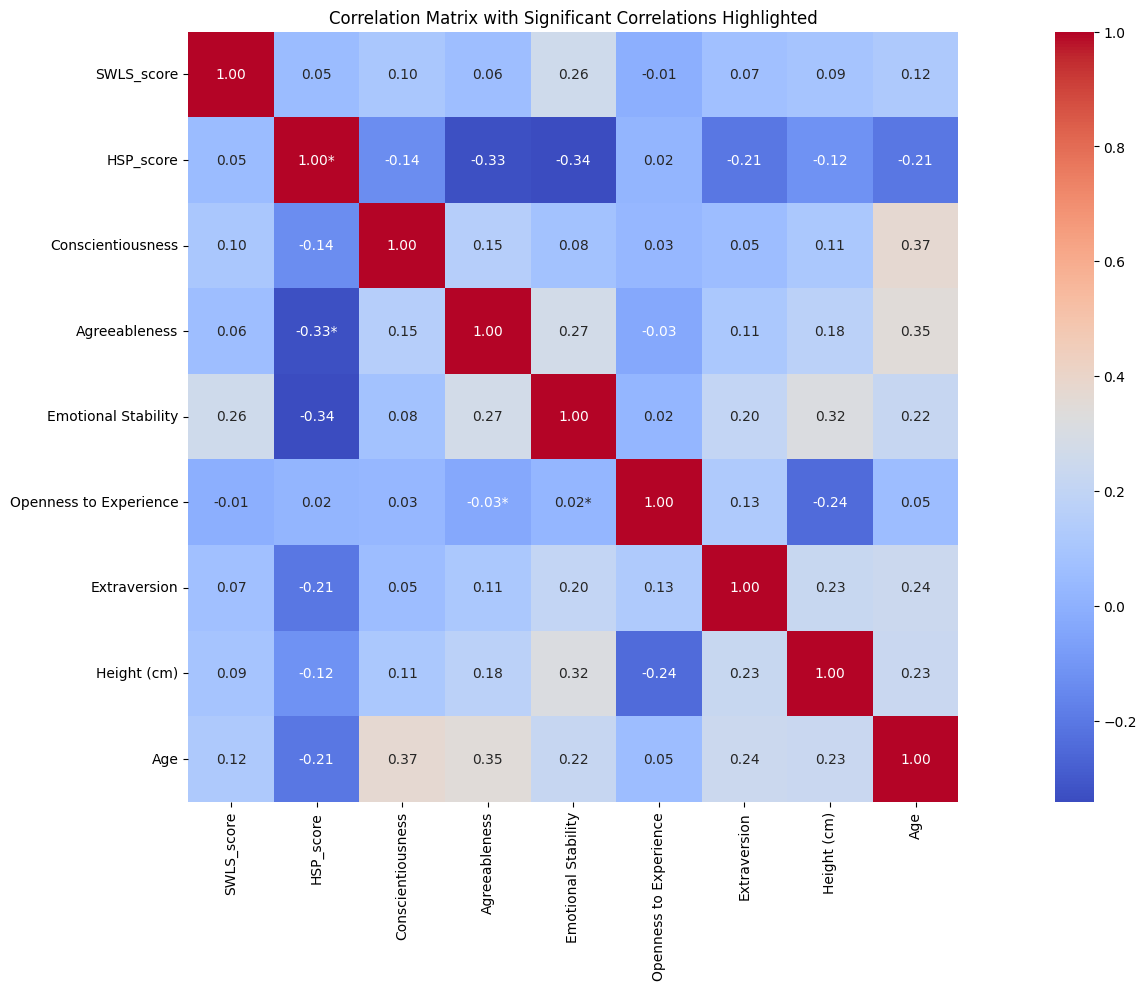

In [ ]:
corr_matrix = df_weekly_onboarding[['SWLS_score', 'HSP_score', 'Conscientiousness', 'Agreeableness',
                  'Emotional Stability', 'Openness to Experience', 'Extraversion',
                  'Height (cm)', 'Age']].corr()
# Calculate p-value matrix
p_matrix = calculate_p_values(corr_matrix)

# Create a mask for correlations with p-values greater than 0.05 (not significant)
#mask_significant = p_matrix > 0.05

# Prepare annotations
annotations = pd.DataFrame(index=corr_matrix.index, columns=corr_matrix.columns)

for i in range(len(corr_matrix.columns)):
    for j in range(len(corr_matrix.columns)):
        corr_value = corr_matrix.iloc[i, j]
        p_value = p_matrix.iloc[i, j]
        annotations.iloc[i, j] = get_annotation(corr_value, p_value)

# Visualize correlation matrix using heatmap
plt.figure(figsize=(25, 10))
heatmap = sns.heatmap(corr_matrix, annot=annotations, fmt='', cmap='coolwarm', square=True)

plt.title('Correlation Matrix with Significant Correlations Highlighted')
plt.show()

#**Multicollinearity**


In [ ]:
#DataFrame
df_weekly_onboarding2 = df_weekly_onboarding[['SWLS_score', 'HSP_score', 'Conscientiousness', 'Agreeableness',
             'Emotional Stability', 'Openness to Experience', 'Extraversion',
             'Height (cm)', 'Age']]

# Function to calculate VIF
def calculate_vif(df):
    vif_data = pd.DataFrame()
    vif_data["Feature"] = df.columns
    vif_data["VIF"] = [variance_inflation_factor(df.values, i) for i in range(len(df.columns))]
    return vif_data

# Calculate VIF
# Calculate VIF
vif_data = calculate_vif(df_weekly_onboarding2)
print(vif_data)

                  Feature         VIF
0              SWLS_score   28.303120
1               HSP_score   51.160909
2       Conscientiousness   31.400964
3           Agreeableness   31.425300
4     Emotional Stability   27.152385
5  Openness to Experience   34.050254
6            Extraversion   11.643717
7             Height (cm)  153.387377
8                     Age   13.603876


#**Chi-Square Test of Association**

In [ ]:
# df is DataFrame
predictive_vars = [
    'The intervention messages were helpful to me in understanding how to improve my indoor environmental satisfaction',
    'Changed location after receiving the noise intervention messages',
    'Put on earphones to mitigate noise distractions after receiving the noise intervention messages',
    'Adjusted Environment to feel thermally comfortable after receiving the temperature intervention messages',
    'The intervention messages were annoying'
]

independent_vars = [
    'Gender',
    'Can you say that you are used to the weather in Singapore?',
    'Can you say that you are satisfied with the weather in Singapore (outdoor weather conditions)?',
    'Do you suffer from sweating in Singapore?',
    'Do you enjoy being outdoor in Singapore?',
    'Do you seem to be aware of subtleties in your environment?',
    'Are you easily overwhelmed by things like bright lights, strong smells, coarse fabrics, or sirens close by?',
    'Do you have a rich, complex inner life?',
    'Do you get rattled when you have a lot to do in a short amount of time?',
    'Are you deeply moved by the arts or music?',
    'Are you annoyed when people try to get you to do too many things at once?',
    'Do you make a point to avoid violent movies and TV shows?',
    'Do you find it unpleasant to have a lot going on at once?',
    'Do changes in your life shake you up?',
    'Do you notice and enjoy delicate or fine scents, tastes, sounds, works of art?',
    'Are you bothered by intense stimuli, like loud noises or chaotic scenes?',
    'When you must compete or be observed while performing a task, do you become so nervous or shaky that you do much worse than you would otherwise?',
    'In most ways my life is close to my ideal.',
    'The conditions of my life are excellent.',
    'I am satisfied with my life.',
    'So far I have gotten the important things I want in life.',
    'If I could live my life over, I would change almost nothing.',
    'Extraverted, enthusiastic', 'Critical, quarrelsome',
    'Dependable, self-disciplined', 'Anxious, easily upset',
    'Open to new experience, complex', 'Reserved, quiet',
    'Sympathetic, warm', 'Disorganized, careless',
    'Calm, emotionally stable', 'Conventional, unreactive',
    'Do you listen to music or radio (without headphones/earbuds) during work or class?',
    'Do you use headphones/earbuds to listen to music?',
    'Do you listen to music using headphones/earbuds when working or studying?',
    'Are you sensitive to noise?',
    'How important is a quiet work or study space to you?'] ####**p-Values for All Categorical Variables**

####**p-Values for All Categorical Variables**

In [ ]:
def chi_square_test_matrix(df, predictive_vars, independent_vars):
    # Initialize a DataFrame to store the p-values
    p_value_matrix = pd.DataFrame(index=predictive_vars, columns=independent_vars)

    for pred_var in predictive_vars:
        for ind_var in independent_vars:
            # Creating a contingency table
            contingency_table = pd.crosstab(df[pred_var], df[ind_var])

            # Performing the Chi-Square test
            chi2, p, dof, expected = chi2_contingency(contingency_table)

            # Storing the p-value in the matrix
            p_value_matrix.loc[pred_var, ind_var] = p

    return p_value_matrix

# Running the function
p_value_matrix = chi_square_test_matrix(df_weekly_onboarding, predictive_vars, independent_vars)


# Displaying the p-value matrix
#print(p_value_matrix)
p_value_matrix_copy = p_value_matrix.transpose().copy()
p_value_matrix.transpose()

,The intervention messages were helpful to me in understanding how to improve my indoor environmental satisfaction,Changed location after receiving the noise intervention messages,Put on earphones to mitigate noise distractions after receiving the noise intervention messages,Adjusted Environment to feel thermally comfortable after receiving the temperature intervention messages,The intervention messages were annoying
Gender,0.051535,0.000004,0.000001,0.00001,0.030098
Can you say that you are used to the weather in Singapore?,0.042394,0.731127,0.294435,0.233244,0.555386
Can you say that you are satisfied with the weather in Singapore (outdoor weather conditions)?,0.011814,0.009809,0.042806,0.051003,0.002161
Do you suffer from sweating in Singapore?,0.010516,0.071699,0.000205,0.022391,0.000279
Do you enjoy being outdoor in Singapore?,0.00001,0.000027,0.000346,0.000039,0.070385
Do you seem to be aware of subtleties in your environment?,0.432942,0.000501,0.002251,0.000467,0.03195
"Are you easily overwhelmed by things like bright lights, strong smells, coarse fabrics, or sirens close by?",0.0051,0.000005,0.197535,0.000013,0.104224
"Do you have a rich, complex inner life?",0.000136,0.000211,0.002851,0.000031,0.380148
Do you get rattled when you have a lot to do in a short amount of time?,0.000016,0.005189,0.000264,0.000012,0.0
Are you deeply moved by the arts or music?,0.003233,0.337849,0.187944,0.003273,0.001796


####**p-Values for Significant Categorical Variables**

In [ ]:
def chi_square_test_matrix(df, predictive_vars, independent_vars):
    # Initialize a DataFrame to store the p-values
    p_value_matrix = pd.DataFrame(index=predictive_vars, columns=independent_vars)

    for pred_var in predictive_vars:
        for ind_var in independent_vars:
            contingency_table = pd.crosstab(df[pred_var], df[ind_var])
            chi2, p, dof, expected = chi2_contingency(contingency_table)
            if p < 0.001:
                p_value_matrix.loc[pred_var, ind_var] = "***"
            elif p < 0.01:
                p_value_matrix.loc[pred_var, ind_var] = "**"
            elif p < 0.05:
                p_value_matrix.loc[pred_var, ind_var] = "*"
            else:
                p_value_matrix.loc[pred_var, ind_var] = ""

    # Drop independent variables with no significance
    p_value_matrix = p_value_matrix.loc[:, (p_value_matrix != "").any()]
    return p_value_matrix

# ✅ Run the function outside its definition
p_value_matrix = chi_square_test_matrix(df_weekly_onboarding, predictive_vars, independent_vars)
p_value_matrix.transpose()


,The intervention messages were helpful to me in understanding how to improve my indoor environmental satisfaction,Changed location after receiving the noise intervention messages,Put on earphones to mitigate noise distractions after receiving the noise intervention messages,Adjusted Environment to feel thermally comfortable after receiving the temperature intervention messages,The intervention messages were annoying
Gender,,***,***,***,*
Can you say that you are used to the weather in Singapore?,*,,,,
Can you say that you are satisfied with the weather in Singapore (outdoor weather conditions)?,*,**,*,,**
Do you suffer from sweating in Singapore?,*,,***,*,***
Do you enjoy being outdoor in Singapore?,***,***,***,***,
Do you seem to be aware of subtleties in your environment?,,***,**,***,*
"Are you easily overwhelmed by things like bright lights, strong smells, coarse fabrics, or sirens close by?",**,***,,***,
"Do you have a rich, complex inner life?",***,***,**,***,
Do you get rattled when you have a lot to do in a short amount of time?,***,**,***,***,***
Are you deeply moved by the arts or music?,**,,,**,**


#**Ordinal Logistic Regression**

**Dependent Variables**

'The noise and/or temperature intervention messages were helpful to me in understanding how to improve my indoor environmental satisfaction.', 'Over the past week, I changed my location after receiving the noise intervention messages. ', 'Over the past week, I put on my earphones to mitigate noise distractions after receiving the noise intervention messages.', 'Over the past week, I changed my location, adjusted the thermostat, fan etc. to feel thermally comfortable after receiving the temperature intervention messages.' 'The intervention messages were annoying.'

In [ ]:
# Use the cleaned DataFrame
y = df_weekly_onboarding['The intervention messages were helpful to me in understanding how to improve my indoor environmental satisfaction']
x = df_weekly_onboarding[['SWLS_score', 'HSP_score', 'Conscientiousness', 'Agreeableness', 'Emotional Stability',
                          'Openness to Experience', 'Extraversion', 'Height (cm)', 'Age']]

# Fit the ordinal logistic regression model
model = OrderedModel(y, x, distr='logit')
results = model.fit(method='bfgs', disp=False)
print(results.summary())


                                                                             OrderedModel Results                                                                            
Dep. Variable:     The intervention messages were helpful to me in understanding how to improve my indoor environmental satisfaction   Log-Likelihood:                -346.84
Model:                                                                                                                  OrderedModel   AIC:                             719.7
Method:                                                                                                           Maximum Likelihood   BIC:                             767.0
Date:                                                                                                               Thu, 24 Apr 2025                                         
Time:                                                                                                                       14:49:

In [ ]:
# Use the renamed column and cleaned DataFrame
y = df_weekly_onboarding['Changed location after receiving the noise intervention messages']
x = df_weekly_onboarding[['SWLS_score', 'HSP_score', 'Conscientiousness', 'Agreeableness',
                          'Emotional Stability', 'Openness to Experience', 'Extraversion',
                          'Height (cm)', 'Age']]

# Fit the ordinal logistic regression model
model = OrderedModel(y, x, distr='logit')
results = model.fit(method='bfgs', disp=False)
print(results.summary())


                                                    OrderedModel Results                                                    
Dep. Variable:     Changed location after receiving the noise intervention messages   Log-Likelihood:                -346.67
Model:                                                                 OrderedModel   AIC:                             719.3
Method:                                                          Maximum Likelihood   BIC:                             766.6
Date:                                                              Thu, 24 Apr 2025                                         
Time:                                                                      14:50:42                                         
No. Observations:                                                               281                                         
Df Residuals:                                                                   268                                         


In [ ]:
# 3rd Dependent Variable - updated column and DataFrame
y = df_weekly_onboarding['Put on earphones to mitigate noise distractions after receiving the noise intervention messages']
x = df_weekly_onboarding[['SWLS_score', 'HSP_score', 'Conscientiousness', 'Agreeableness',
                          'Emotional Stability', 'Openness to Experience', 'Extraversion',
                          'Height (cm)', 'Age']]

# Fit the ordinal logistic regression model
model = OrderedModel(y, x, distr='logit')
results = model.fit(method='bfgs', disp=False)
print(results.summary())


                                                                    OrderedModel Results                                                                   
Dep. Variable:     Put on earphones to mitigate noise distractions after receiving the noise intervention messages   Log-Likelihood:                -372.57
Model:                                                                                                OrderedModel   AIC:                             771.1
Method:                                                                                         Maximum Likelihood   BIC:                             818.4
Date:                                                                                             Thu, 24 Apr 2025                                         
Time:                                                                                                     14:51:22                                         
No. Observations:                                               

In [ ]:
# 4th Dependent Variable
y = df_weekly_onboarding['Adjusted Environment to feel thermally comfortable after receiving the temperature intervention messages']
x = df_weekly_onboarding[['SWLS_score', 'HSP_score', 'Conscientiousness', 'Agreeableness',
                          'Emotional Stability', 'Openness to Experience', 'Extraversion',
                          'Height (cm)', 'Age']]

# Fit the model
model = OrderedModel(y, x, distr='logit')
results = model.fit(method='bfgs', disp=False)
print(results.summary())


                                                                        OrderedModel Results                                                                        
Dep. Variable:     Adjusted Environment to feel thermally comfortable after receiving the temperature intervention messages   Log-Likelihood:                -377.77
Model:                                                                                                         OrderedModel   AIC:                             781.5
Method:                                                                                                  Maximum Likelihood   BIC:                             828.8
Date:                                                                                                      Thu, 24 Apr 2025                                         
Time:                                                                                                              14:54:52                                         
No. Observ

In [ ]:
# 5th Dependent Variable
y = df_weekly_onboarding['The intervention messages were annoying']
x = df_weekly_onboarding[['SWLS_score', 'HSP_score', 'Conscientiousness', 'Agreeableness',
                          'Emotional Stability', 'Openness to Experience', 'Extraversion',
                          'Height (cm)', 'Age']]

# Fit the model
model = OrderedModel(y, x, distr='logit')
results = model.fit(method='bfgs', disp=False)
print(results.summary())


                                        OrderedModel Results                                       
Dep. Variable:     The intervention messages were annoying   Log-Likelihood:                -354.85
Model:                                        OrderedModel   AIC:                             735.7
Method:                                 Maximum Likelihood   BIC:                             783.0
Date:                                     Thu, 24 Apr 2025                                         
Time:                                             14:57:53                                         
No. Observations:                                      281                                         
Df Residuals:                                          268                                         
Df Model:                                                9                                         
                             coef    std err          z      P>|z|      [0.025      0.975]
---------